# Learning to Win at Snakes & Ladders
## A comparative study of tabular and deep reinforcement learning

An agent learns to play a snakes-and-ladders style board game. In the core game the agent
**chooses** the dice value (1–6) every turn; in the extension the die is random.

This notebook covers:

| # | Section |
|---|---------|
| 1 | Environment search and the custom Gymnasium environment |
| 2 | MDP formulation, reward design and the invalid-move rule |
| 3 | Boards, baselines (random policy, BFS shortest path, value iteration optimum) |
| 4 | The algorithms: **why DQN, PPO and A2C** (stable-baselines3), plus tabular Q-Learning and SARSA |
| 5 | Core experiments on the 30 / 50 / 100 square boards (3 seeds each) |
| 6 | Results table, training curves, Q-Learning vs SARSA |
| 7 | Demonstration: before training, during training, after training |
| 8 | Random dice: Challenge 1 / Environment B (stochastic transitions), Challenge 2 (one-time snake shield), Challenge 4 (two players) |
| 9 | Challenge 5: DQN vs tabular Q-Learning on larger boards |
| 10 | Challenge 3 / Environment C: dynamic board (new snakes and ladders every episode) |
| 11 | Challenge 6 and extra studies: reward design, fewer episodes, snake/ladder density |
| 12 | Discussion: ten research questions, and when a classical planner such as BFS is enough |

**Scope.** Section 2 defines the environment: state, action, reward table and transition rules. Sections 4–6 cover
ε-greedy training over many episodes, evaluation on separate games, and the learning curves. Sections 5–6 run three
benchmark boards (30 squares / 3 snakes / 3 ladders, 50/5/5 and 100/8/8). Section 7 shows the agent before, during
and after training. Six extensions follow: random dice, a one-time snake shield and a two-player race (Section 8),
larger boards (Section 9), a board that changes every episode (Section 10) and reward design (Section 11.1).
Section 12 discusses ten research questions and when a classical planner such as BFS is the better tool.

> **Re-running.** Training results are cached in `results/` (and SB3 models in `models/`). With `RETRAIN = False` the
> notebook reloads them in seconds; set `RETRAIN = True` to train everything from scratch (about an hour on a laptop CPU).

## 1. Is there a ready-made Gymnasium environment?

Before writing code I searched for an existing Gymnasium implementation of Snakes & Ladders. The
[Gymnasium paper and repository](https://arxiv.org/abs/2407.17032) do not include one, and the closest public
projects are either the *Snake* arcade game (e.g. `colurw/snake_PPO`) or old `gym` (pre-Gymnasium) snakes-and-ladders
toys where the die is always random. None matches this project, where:

* the agent **chooses** the dice value (action space = 6 values),
* moves past the last square are **invalid** with a documented penalty,
* a fixed reward table with ladder bonuses and snake penalties is used,
* snakes/ladders are generated for 30 / 50 / 100 square boards.

So I wrote a custom environment that follows the Gymnasium API (`reset`, `step` returning
`obs, reward, terminated, truncated, info`, `observation_space`, `action_space`) and checked it with both
`gymnasium.utils.env_checker.check_env` and `stable_baselines3.common.env_checker.check_env`.
This makes it directly usable by **stable-baselines3**.

*About SBX (SB3 + JAX).* SBX has the same API as SB3 (`from sbx import DQN, PPO`), but it has no A2C, and JAX
has no native-Windows GPU build. The networks here are tiny MLPs where the CPU is the fastest device anyway, so I use
the PyTorch SB3. Switching DQN/PPO to SBX only means changing the import.

In [1]:
import os, time, pickle, warnings
from collections import Counter, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyArrowPatch
from IPython.display import display

import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env as gym_check_env
import torch
import stable_baselines3 as sb3
from stable_baselines3 import DQN, PPO, A2C
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.env_checker import check_env as sb3_check_env

warnings.filterwarnings("ignore")
torch.set_num_threads(1)          # tiny MLPs: a single CPU thread is the fastest option

RETRAIN = False                    # True = train everything again, False = reuse cached results when present
RESULTS_DIR, MODELS_DIR = "results", "models"
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(MODELS_DIR, exist_ok=True)

SEEDS = [0, 1, 2]                  # every experiment is repeated with 3 training seeds
GAMMA = 0.99
ALGOS = ["Q-Learning", "SARSA", "DQN", "PPO", "A2C"]
COLORS = {"Q-Learning": "#1f77b4", "SARSA": "#ff7f0e", "DQN": "#2ca02c", "PPO": "#d62728", "A2C": "#9467bd",
          "Random": "#7f7f7f", "Optimal": "black"}
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})


def cached(name, fn):
    # Run fn() once and pickle the result; later runs load it unless RETRAIN is True.
    path = os.path.join(RESULTS_DIR, name + ".pkl")
    if not RETRAIN and os.path.exists(path):
        with open(path, "rb") as f:
            print(f"[cache] loaded {path}")
            return pickle.load(f)
    t0 = time.time()
    out = fn()
    with open(path, "wb") as f:
        pickle.dump(out, f)
    print(f"[cache] saved {path} ({time.time() - t0:.0f}s)")
    return out


print(f"gymnasium {gym.__version__} | stable-baselines3 {sb3.__version__} | torch {torch.__version__}")

gymnasium 1.4.0 | stable-baselines3 2.9.2 | torch 2.15.0+cpu


## 2. MDP formulation

| Element | Core game (agent chooses the die) | Random-dice extension (Challenge 1) |
|---|---|---|
| **State** $s$ | current square $p \in \{1,\dots,N\}$ | pair $(p, d)$: square and the die value just rolled, $d\in\{1..6\}$ |
| **Action** $a$ | dice value $\{1,\dots,6\}$ (index 0–5 in code) | $\{\text{stay}, \text{move}\}$: skip the turn or move $d$ squares |
| **Transition** | deterministic: $p' = \text{jump}(p+a)$ | $p' = \text{jump}(p+d)$ if move, $p'=p$ if stay; next $d' \sim U\{1..6\}$ |
| **Terminal** | $p' = N$ | $p' = N$ |
| **Truncation** | after `max_steps` moves ($\lfloor N/3 \rfloor$) | after $4N$ moves |

**Transition function.** Target $= p + a$. If target $> N$ the move is **invalid**: the
agent stays on $p$ and receives $-10$ (*penalise-and-stay* rule). Otherwise, if the target is a snake head or ladder
foot, the jump is applied immediately. The function returns the new state, the reward and the terminal flag.

**Why is it an MDP?** The next square and reward depend only on the current square and the chosen action (plus, in
the random version, the current roll, which is part of the state). The history of how the agent got there does not matter, so
the **Markov property** holds. The episode limit is not part of the state, but it is only a training cut-off
(`truncated=True`, so it is not treated as a real terminal state when bootstrapping).

**Reward function.** All main experiments use the standard reward table below, called **R-v0**. An alternative **R-v1** (no ladder bonus) is studied in Sections 3.3 and 11.1 to show how reward design changes
the learned policy:

| Situation | **R-v0 (standard, used)** | R-v1 (alternative) |
|---|---|---|
| reach final square | +100 | +100 |
| land on ladder | **+20** | **−1** (an ordinary move; the progress is its own reward) |
| normal square | −1 | −1 |
| land on snake | −20 | −20 |
| invalid move (beyond $N$) | −10, stay | −10, stay |
| stay (random-dice mode only) | −1 | −1 |

**Objective and the fairness of the BFS comparison.** The RL objective is the **maximum expected discounted return**
($\gamma = 0.99$). BFS minimises the **number of rolls**. The two coincide when the fastest route is also the most
rewarding one. That holds on the three benchmark boards (checked exactly with value iteration in Section 3.2), but not
on every board: a $+20$ ladder can make a one-move detour worth it (Section 9 shows one), and on boards with long
jumps the bonus can even be farmed forever (Section 3.3). So convergence is measured against the **value-iteration
optimum of the same reward**, and BFS is reported next to it.

In [2]:
REWARDS_V0 = dict(goal=100.0, ladder=20.0, normal=-1.0, snake=-20.0, invalid=-10.0, stay=-1.0)   # standard table (used)
REWARDS_V1 = dict(goal=100.0, ladder=-1.0, normal=-1.0, snake=-20.0, invalid=-10.0, stay=-1.0)   # alternative


def transition(pos, dice, n, jumps, rewards=REWARDS_V0):
    # Deterministic transition of the board. Returns (next_pos, reward, event).
    target = pos + dice
    if target > n:                                   # invalid move: penalised, agent stays where it is
        return pos, rewards["invalid"], "invalid"
    if target == n:
        return n, rewards["goal"], "goal"
    if target in jumps:                              # snake or ladder applied immediately
        dest = jumps[target]
        return (dest, rewards["ladder"], "ladder") if dest > target else (dest, rewards["snake"], "snake")
    return target, rewards["normal"], "normal"


def shield_transition(pos, dice, use, left, n, jumps, rewards=REWARDS_V0):
    # Challenge 2: move by the rolled value; if the move lands on a snake head, `use`=1 and an unused
    # shield (`left`=1), the snake is ignored and the shield is spent. Returns (next_pos, reward, event, left).
    target = pos + dice
    if use and left and target < n and target in jumps and jumps[target] < target:
        return target, rewards["normal"], "shielded", 0
    nxt, r, ev = transition(pos, dice, n, jumps, rewards)
    return nxt, r, ev, left


class DiceBoardEnv(gym.Env):
    # Snakes & Ladders dice game as a Gymnasium environment.
    #   core mode   : action a in {0..5} = "move a+1 squares" (the agent chooses the dice value)
    #   random dice : the env rolls the die and shows it in the observation; action 0 = stay, 1 = move
    #   shield      : random dice, no stay; action 0 = move, 1 = move and spend the one-time snake shield
    #                 if this move would land on a snake (Challenge 2); shield left is part of the state
    #   observation : 'onehot'   -> one-hot square (N) [+ one-hot roll (6)] [+ shield-left flag]
    #                 'features' -> 26 hand-made features (Challenges 5 and 3)
    #   dynamic     : (n_snakes, n_ladders) -> a new random board is generated at every reset (Challenge 3)
    #   reward_scale: multiplies every reward (used only to train DQN, see Section 4.4)
    metadata = {"render_modes": ["ansi"]}

    def __init__(self, n=30, jumps=None, max_steps=None, random_dice=False, rewards=None,
                 obs_mode="onehot", shaping=0.0, reward_scale=1.0, dynamic=None, shield=False, render_mode=None):
        super().__init__()
        self.n, self.jumps = n, dict(jumps or {})
        self.max_steps = max_steps or 2 * n
        self.random_dice, self.obs_mode, self.shaping = random_dice or shield, obs_mode, shaping
        self.reward_scale, self.dynamic, self.shield = reward_scale, dynamic, shield
        self.rewards = {**REWARDS_V0, **(rewards or {})}
        self.render_mode = render_mode
        self.n_rolls = 6 if self.random_dice else 1
        self.n_flags = 2 if shield else 1
        self.action_space = spaces.Discrete(2 if self.random_dice else 6)
        if obs_mode == "features":
            assert not self.random_dice
            self.observation_space = spaces.Box(-1.0, 1.0, (2 + 6 * 4,), np.float32)
        else:
            dim = n + (6 if self.random_dice else 0) + (1 if shield else 0)
            self.observation_space = spaces.Box(0.0, 1.0, (dim,), np.float32)
        self.pos, self.t, self.roll, self.shield_left = 1, 0, 0, 0

    # ---- discrete state id (used by the tabular agents and value iteration)
    @property
    def n_states(self):
        return self.n * self.n_rolls * self.n_flags

    def state_index(self):
        r = self.roll - 1 if self.random_dice else 0
        return ((self.pos - 1) * self.n_rolls + r) * self.n_flags + (self.shield_left if self.shield else 0)

    # ---- observations
    def _features(self):
        f = [self.pos / self.n, min(self.n - self.pos, 12) / 12]
        for d in range(1, 7):
            dest, _, ev = transition(self.pos, d, self.n, self.jumps, self.rewards)
            f += [float(ev != "invalid"), float(ev == "ladder"), float(ev == "snake"), (dest - self.pos) / self.n]
        return np.asarray(f, np.float32)

    def _obs(self):
        if self.obs_mode == "features":
            return self._features()
        o = np.zeros(self.observation_space.shape, np.float32)
        o[self.pos - 1] = 1.0
        if self.random_dice:
            o[self.n + self.roll - 1] = 1.0
        if self.shield:
            o[-1] = float(self.shield_left)
        return o

    def _potential(self, pos):          # potential-based shaping (Section 11.1); Phi(goal) = 0
        return 0.0 if pos == self.n else self.shaping * (pos - 1) / (self.n - 1)

    def _roll(self):
        self.roll = int(self.np_random.integers(1, 7)) if self.random_dice else 0

    # ---- Gymnasium API
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if self.dynamic:                                   # Challenge 3: new snakes and ladders every episode
            self.jumps = generate_board(self.n, *self.dynamic, seed=int(self.np_random.integers(2**31)))
        self.pos, self.t = 1, 0
        self.shield_left = 1 if self.shield else 0
        self._roll()
        return self._obs(), {"pos": self.pos}

    def step(self, action):
        action, prev, saved = int(action), self.pos, 0
        if self.shield:
            dice = self.roll
            self.pos, reward, event, self.shield_left = shield_transition(
                self.pos, dice, action, self.shield_left, self.n, self.jumps, self.rewards)
            if event == "shielded":
                saved = self.pos - self.jumps[self.pos]           # squares the shield saved
            self._roll()
        elif self.random_dice:
            dice = self.roll
            if action == 0:
                reward, event = self.rewards["stay"], "stay"
            else:
                self.pos, reward, event = transition(self.pos, dice, self.n, self.jumps, self.rewards)
            self._roll()
        else:
            dice = action + 1
            self.pos, reward, event = transition(self.pos, dice, self.n, self.jumps, self.rewards)
        if self.shaping:
            reward += GAMMA * self._potential(self.pos) - self._potential(prev)
        reward *= self.reward_scale
        self.t += 1
        terminated = self.pos == self.n
        truncated = (not terminated) and self.t >= self.max_steps
        info = {"pos": self.pos, "event": event, "dice": dice, "is_success": terminated, "saved": saved}
        return self._obs(), float(reward), terminated, truncated, info

    def render(self):
        return f"t={self.t} square={self.pos}" + (f" roll={self.roll}" if self.random_dice else "")


def make_env(**kw):
    # Factory used by SB3 and the training helpers: kw may name another env class with env_cls=...
    kw = dict(kw)
    return kw.pop("env_cls", DiceBoardEnv)(**kw)

## 3. Boards and baselines

### 3.1 Board generation
Snakes and ladders are placed at random (fixed seed per board, so every algorithm sees the same board). Rules: no jump
starts or ends on square 1 or $N$; each square holds at most one endpoint, so jumps never chain; jump length is between
$N/10$ and $N/3$; and the goal must be reachable (checked with BFS).

In [3]:
def bfs_shortest_path(n, jumps):
    # Minimum number of chosen-dice moves from square 1 to n. Returns (moves, [(from, dice, to), ...]).
    prev, q = {1: None}, deque([1])
    while q:
        s = q.popleft()
        if s == n:
            break
        for d in range(1, 7):
            t, _, ev = transition(s, d, n, jumps)
            if ev != "invalid" and t not in prev:
                prev[t] = (s, d)
                q.append(t)
    if n not in prev:
        return None, None
    path, s = [], n
    while prev[s] is not None:
        p, d = prev[s]
        path.append((p, d, s))
        s = p
    return len(path), path[::-1]


def generate_board(n, n_snakes, n_ladders, seed=0, min_span=None, max_span=None):
    rng = np.random.default_rng(seed)
    min_span = min_span or max(3, n // 10)
    max_span = max_span or max(min_span + 2, n // 3)
    for _ in range(1000):
        used, jumps = {1, n}, {}
        for kind, count in (("ladder", n_ladders), ("snake", n_snakes)):
            placed = tries = 0
            while placed < count and tries < 5000:
                tries += 1
                a, b = sorted(int(x) for x in rng.choice(np.arange(2, n), 2, replace=False))
                if not (min_span <= b - a <= max_span):
                    continue
                start, end = (a, b) if kind == "ladder" else (b, a)
                if start in used or end in used:
                    continue
                jumps[start] = end
                used |= {start, end}
                placed += 1
        if len(jumps) == n_snakes + n_ladders and bfs_shortest_path(n, jumps)[0] is not None:
            return dict(sorted(jumps.items()))
    raise RuntimeError("could not generate a valid board")


BOARD_SPECS = [("Board 30", 30, 3, 3, 1), ("Board 50", 50, 5, 5, 2), ("Board 100", 100, 8, 8, 3)]
BOARDS = {name: dict(n=n, jumps=generate_board(n, s, l, seed), max_steps=n // 3)
          for name, n, s, l, seed in BOARD_SPECS}

for name, b in BOARDS.items():
    ladders = {k: v for k, v in b["jumps"].items() if v > k}
    snakes = {k: v for k, v in b["jumps"].items() if v < k}
    print(f"{name}: N={b['n']}, episode limit={b['max_steps']} moves")
    print(f"   ladders: {ladders}\n   snakes : {snakes}")

# environment sanity checks (Gymnasium + SB3 checkers)
for kw in (BOARDS["Board 30"], dict(BOARDS["Board 30"], random_dice=True), dict(BOARDS["Board 30"], obs_mode="features")):
    gym_check_env(DiceBoardEnv(**kw), skip_render_check=True)
    sb3_check_env(DiceBoardEnv(**kw), warn=True)
print("check_env passed for core, random-dice and feature versions")

Board 30: N=30, episode limit=10 moves
   ladders: {13: 20, 22: 25, 24: 28}
   snakes : {9: 2, 11: 6, 14: 5}
Board 50: N=50, episode limit=16 moves
   ladders: {14: 28, 16: 21, 22: 37, 30: 41, 33: 47}
   snakes : {17: 10, 29: 24, 31: 18, 32: 23, 43: 27}
Board 100: N=100, episode limit=33 moves
   ladders: {4: 26, 11: 34, 15: 30, 25: 58, 38: 52, 48: 62, 59: 86, 75: 95}
   snakes : {39: 16, 53: 28, 79: 60, 80: 69, 91: 81, 93: 61, 94: 76, 97: 78}
check_env passed for core, random-dice and feature versions


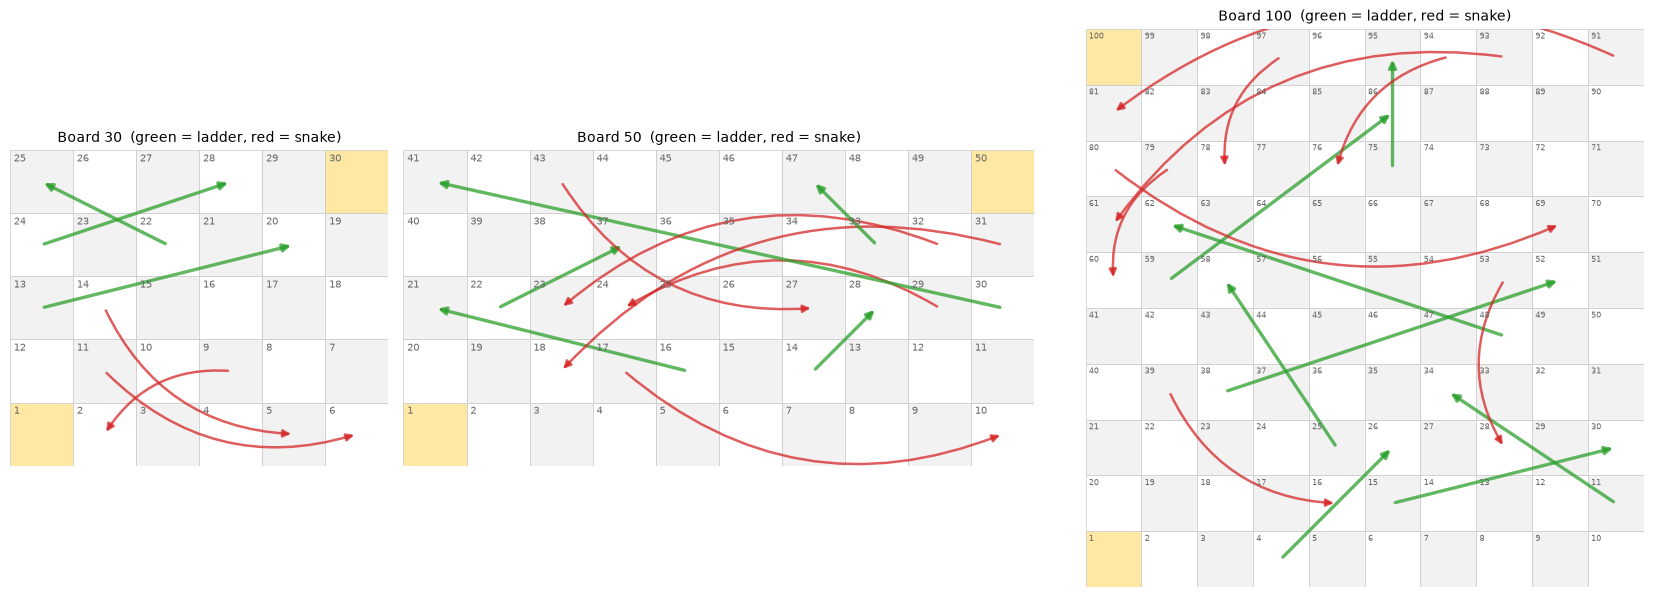

In [4]:
def square_xy(sq, cols):
    r, c = divmod(sq - 1, cols)
    if r % 2:
        c = cols - 1 - c                       # boustrophedon layout like a real board
    return c + 0.5, r + 0.5


def draw_board(board, ax, path=None, title="", path_color="#1f77b4"):
    n, jumps = board["n"], board["jumps"]
    cols = 6 if n <= 30 else 10
    rows = -(-n // cols)
    for sq in range(1, n + 1):
        x, y = square_xy(sq, cols)
        face = "#ffe8a3" if sq in (1, n) else ("#f2f2f2" if (int(x) + int(y)) % 2 == 0 else "white")
        ax.add_patch(Rectangle((x - .5, y - .5), 1, 1, facecolor=face, edgecolor="#c8c8c8", lw=.5))
        ax.text(x - .44, y + .44, str(sq), fontsize=6 if n > 50 else 7, va="top", ha="left", color="#666")
    for s, e in jumps.items():
        ladder = e > s
        ax.add_patch(FancyArrowPatch(square_xy(s, cols), square_xy(e, cols), arrowstyle="-|>", mutation_scale=11,
                                     color="#2ca02c" if ladder else "#d62728", lw=2.4 if ladder else 1.8, alpha=.75,
                                     connectionstyle="arc3,rad=0" if ladder else "arc3,rad=.3"))
    if path is not None:
        pts = np.array([square_xy(p, cols) for p in path])
        ax.plot(pts[:, 0], pts[:, 1], "o-", color=path_color, lw=1.6, ms=4, zorder=5, alpha=.9)
        ax.plot(*pts[-1], "*", color=path_color, ms=12, zorder=6)
    ax.set_xlim(0, cols); ax.set_ylim(0, rows); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [6, 10, 10]})
for ax, (name, b) in zip(axes, BOARDS.items()):
    draw_board(b, ax, title=f"{name}  (green = ladder, red = snake)")
plt.tight_layout(); plt.show()

### 3.2 Baselines: random policy, BFS shortest path and the exact optimum

* **Random policy** (*before training*): picks a dice value uniformly at random.
* **BFS**: the minimum number of rolls, a classical graph search over the 6 dice choices.
* **Value iteration (VI)**: since the model is known, dynamic programming gives the exact optimal $Q^*$ of the
  reward function. RL agents do **not** use the model; VI only provides the yardstick.

In [5]:
def build_model(env):
    # Tabular model (P[a, s, s'], R[s, a], terminal[s]) of an env; used only by value iteration.
    nS, nA, n, nR, nF = env.n_states, env.action_space.n, env.n, env.n_rolls, env.n_flags
    idx = lambda p, r, f: ((p - 1) * nR + r) * nF + f           # same ordering as env.state_index()
    P, R, terminal = np.zeros((nA, nS, nS)), np.zeros((nS, nA)), np.zeros(nS, bool)
    for pos in range(1, n + 1):
        for r in range(nR):
            for f in range(nF):
                s = idx(pos, r, f)
                terminal[s] = pos == n
                for a in range(nA):
                    nf = f
                    if env.shield:
                        nxt, rew, _, nf = shield_transition(pos, r + 1, a, f, n, env.jumps, env.rewards)
                    elif env.random_dice:
                        nxt, rew = (pos, env.rewards["stay"]) if a == 0 else transition(pos, r + 1, n, env.jumps, env.rewards)[:2]
                    else:
                        nxt, rew, _ = transition(pos, a + 1, n, env.jumps, env.rewards)
                    for r2 in range(nR):                         # next roll is uniform (or absent)
                        P[a, s, idx(nxt, r2, nf)] += 1 / nR
                    R[s, a] = rew
    return P, R, terminal


def value_iteration(env, gamma=GAMMA, tol=1e-8):
    P, R, terminal = build_model(env)
    Q = np.zeros_like(R)
    while True:
        V = np.where(terminal, 0.0, Q.max(1))
        Qn = R + gamma * np.einsum("asn,n->sa", P, V)
        Qn[terminal] = 0.0
        if np.abs(Qn - Q).max() < tol:
            return Qn
        Q = Qn


def evaluate(policy, env, episodes=100, seed=10_000):
    # Run `episodes` games with policy(env) -> action; return mean statistics.
    rows = []
    for i in range(episodes):
        env.reset(seed=seed + i)
        total, done, ev = 0.0, False, Counter()
        while not done:
            _, r, term, trunc, info = env.step(policy(env))
            total += r; ev[info["event"]] += 1; done = term or trunc
            ev["saved_sq"] += info.get("saved", 0); ev["bumped"] += info.get("bumped", 0)
        rows.append(dict(ret=total, moves=env.t, success=float(info["is_success"]), snakes=ev["snake"],
                         ladders=ev["ladder"], invalid=ev["invalid"], stays=ev["stay"], shielded=ev["shielded"],
                         saved=ev["saved_sq"], bumps=ev["bump"], bumped=ev["bumped"]))
    return pd.DataFrame(rows).mean().to_dict()


def rollout(policy, env, seed=0):
    # Play one game and keep the squares visited (incl. the square where a jump started) and a text trace.
    env.reset(seed=seed)
    squares, trace, total, done = [env.pos], [], 0.0, False
    while not done:
        prev = env.pos
        _, r, term, trunc, info = env.step(policy(env))
        if info["event"] in ("ladder", "snake"):
            squares.append(prev + info["dice"])
        squares.append(env.pos)
        trace.append((prev, info["dice"], info["event"], env.pos, r))
        total += r; done = term or trunc
    return dict(squares=squares, trace=trace, ret=total, moves=env.t, success=bool(term))


def show_trace(ro, label):
    steps = "  ".join(f"{p}-[{d}]->{q}{'' if e == 'normal' else '(' + e + ')'}" for p, d, e, q, _ in ro["trace"])
    print(f"{label}: {ro['moves']} moves, return {ro['ret']:+.0f}, reached goal: {ro['success']}\n   {steps}")


random_policy = lambda env: int(env.action_space.sample())
q_policy = lambda Q: (lambda env: int(np.argmax(Q[env.state_index()])))

OPTIMAL, RANDOM = {}, {}
for name, b in BOARDS.items():
    env = DiceBoardEnv(**b)
    env.action_space.seed(0)
    bfs_moves, bfs_path = bfs_shortest_path(b["n"], b["jumps"])
    Qstar = value_iteration(env)
    ro = rollout(q_policy(Qstar), env)
    OPTIMAL[name] = dict(bfs=bfs_moves, bfs_path=bfs_path, Q=Qstar, moves=ro["moves"], ret=ro["ret"], rollout=ro)
    RANDOM[name] = evaluate(random_policy, env, 1000)
    RANDOM[name]["rollout"] = rollout(random_policy, env, seed=1)

display(pd.DataFrame({name: {"BFS min moves": OPTIMAL[name]["bfs"],
                             "VI-optimal moves": OPTIMAL[name]["moves"],
                             "VI-optimal return": OPTIMAL[name]["ret"],
                             "Random: success %": 100 * RANDOM[name]["success"],
                             "Random: avg moves": RANDOM[name]["moves"],
                             "Random: avg return": RANDOM[name]["ret"]} for name in BOARDS}).round(2))
for name in BOARDS:
    print(f"{name} BFS path: " + "  ".join(f"{p}-[{d}]->{q}" for p, d, q in OPTIMAL[name]["bfs_path"]))

,Board 30,Board 50,Board 100
BFS min moves,4.00,5.00,8.00
VI-optimal moves,4.00,5.00,8.00
VI-optimal return,139.00,138.00,156.00
Random: success %,30.90,49.60,48.00
Random: avg moves,9.48,14.12,28.59
Random: avg return,1.35,22.19,2.00


Board 30 BFS path: 1-[6]->7  7-[6]->20  20-[2]->25  25-[5]->30
Board 50 BFS path: 1-[1]->2  2-[6]->8  8-[6]->28  28-[5]->47  47-[3]->50
Board 100 BFS path: 1-[3]->26  26-[6]->32  32-[6]->52  52-[2]->54  54-[5]->86  86-[3]->89  89-[6]->95  95-[5]->100


### 3.3 Is the standard reward safe? A check for reward hacking

With a known model, value iteration shows what an optimal agent would do under each reward function. The table
compares R-v0 (standard) and R-v1 on the three benchmark boards, and on one extra board with long jumps (spans up to
$N/2$) that is **not** used in the main experiments.

moves                     \
reward              R-v0 (standard, used) R-v1 (alternative)   
board                                                          
Board 100                               8                  8   
Board 30                                4                  4   
Board 50                                5                  5   
Long-jump board 100                   200                  5   

                             reached_goal                     
reward              R-v0 (standard, used) R-v1 (alternative)  
board                                                         
Board 100                            True               True  
Board 30                             True               True  
Board 50                             True               True  
Long-jump board 100                 False               True

R-v0 optimal play on the long-jump board (first 14 moves):
  1-[4]->13(ladder)  13-[2]->30(ladder)  30-[6]->36(normal)  36-[6]->42(normal)  42-[6]->62(ladder)  62-[3]->23(snake)  23-[3]->4(snake)  4-[1]->13(ladder)  13-[2]->30(ladder)  30-[6]->36(normal)  36-[6]->42(normal)  42-[6]->62(ladder)  62-[3]->23(snake)  23-[3]->4(snake)


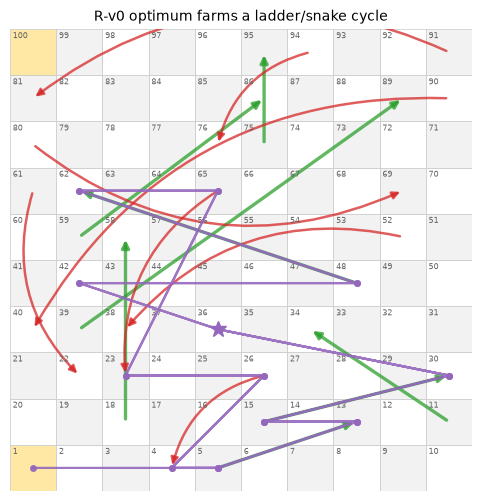

In [6]:
HACK_BOARD = dict(n=100, jumps=generate_board(100, 8, 8, seed=3, min_span=8, max_span=50), max_steps=200)

rows = []
for name, b in {**BOARDS, "Long-jump board 100": HACK_BOARD}.items():
    for rname, R in (("R-v0 (standard, used)", REWARDS_V0), ("R-v1 (alternative)", REWARDS_V1)):
        env = DiceBoardEnv(**dict(b, max_steps=200), rewards=R)
        ro = rollout(q_policy(value_iteration(env)), env)
        rows.append(dict(board=name, reward=rname, moves=ro["moves"], reached_goal=ro["success"], ret=ro["ret"]))
display(pd.DataFrame(rows).pivot(index="board", columns="reward", values=["moves", "reached_goal"]))

env = DiceBoardEnv(**HACK_BOARD, rewards=REWARDS_V0)
ro = rollout(q_policy(value_iteration(env)), env)
loop = [f"{p}-[{d}]->{q}({e})" for p, d, e, q, _ in ro["trace"][:14]]
print("R-v0 optimal play on the long-jump board (first 14 moves):\n  " + "  ".join(loop))
fig, ax = plt.subplots(figsize=(6, 6))
draw_board(HACK_BOARD, ax, path=ro["squares"][:30], title="R-v0 optimum farms a ladder/snake cycle", path_color="#9467bd")
plt.show()

On the long-jump board the R-v0 optimum **never reaches the goal**. A cycle *ladder (+20) → snake (−20) →
short walk back to the ladder* earns more discounted reward than finishing the game, because $\gamma<1$ makes the
early $+20$ worth more than the later $-20$. This is the classic *reward hacking* problem: a bonus for an
intermediate event that can be repeated changes the optimal policy.

On the **three benchmark boards** the standard R-v0 is safe: its optimum reaches the goal on the same route as BFS. So the
main experiments use R-v0, and they measure convergence against this exact optimum. R-v1 is
safe on every board by construction, because nothing but the goal pays a positive reward. Section 11.1 compares the
two rewards (plus potential-based shaping) in a learning experiment.

## 4. Algorithms

### 4.1 Why these three deep RL algorithms?

The action space is **discrete** (6 dice values, or stay/move), the state is low-dimensional, and the environment is
very cheap to simulate. I wanted one algorithm from each of the three main families of model-free deep RL that
support discrete actions in stable-baselines3:

| | **DQN** | **A2C** | **PPO** |
|---|---|---|---|
| Family | value-based | policy gradient / actor-critic | policy gradient / actor-critic with trust region |
| Data | **off-policy**, replay buffer | **on-policy**, parallel envs | **on-policy**, parallel envs, several epochs per batch |
| Policy | greedy w.r.t. $Q_\theta$, **ε-greedy** exploration | stochastic $\pi_\theta(a\mid s)$ + entropy bonus | stochastic $\pi_\theta(a\mid s)$ + entropy bonus |
| Why chosen | deep version of the required Q-Learning, so tabular vs deep can be compared directly; replay makes it sample-efficient | simplest actor-critic; baseline for PPO | most widely used DRL algorithm, robust defaults; comparing with A2C isolates the effect of clipping and batch reuse |

Algorithms for continuous actions (SAC, TD3, DDPG) do not apply to a 6-way discrete choice, so they were excluded.

### 4.2 The idea of each algorithm

**DQN (Deep Q-Network, Mnih et al. 2015).** A neural network $Q_\theta(s,a)$ replaces the Q-table. Transitions
$(s,a,r,s')$ go into a **replay buffer**; random minibatches minimise the TD error

$$\mathcal L(\theta)=\big(r+\gamma\max_{a'}Q_{\theta^-}(s',a')-Q_\theta(s,a)\big)^2 ,$$

where $\theta^-$ is a **target network** copied from $\theta$ every few hundred steps. Replay breaks the correlation
between consecutive samples and reuses data; the target network stops the regression target from moving at every update.
Exploration is ε-greedy with ε decaying linearly from 1 to 0.05.

**A2C (Advantage Actor-Critic, synchronous version of A3C, Mnih et al. 2016).** Two heads: an **actor**
$\pi_\theta(a\mid s)$ and a **critic** $V_w(s)$. Several environments run in parallel for $n$ steps, then

$$\nabla_\theta J \approx \textstyle\sum_t \nabla_\theta\log\pi_\theta(a_t\mid s_t)\,\hat A_t,\qquad
\hat A_t=\sum_{k=0}^{n-1}\gamma^k r_{t+k}+\gamma^n V_w(s_{t+n})-V_w(s_t)$$

The advantage tells the actor whether the action was better than expected; the critic is trained by regression on
the same returns; an entropy bonus keeps the policy exploring. Each batch is used for a **single** gradient step.

**PPO (Proximal Policy Optimization, Schulman et al. 2017).** Same actor-critic structure, but each rollout is reused
for **several epochs** of minibatch updates. To keep the new policy close to the one that collected the data, it
maximises the **clipped surrogate**

$$L^{CLIP}(\theta)=\mathbb E_t\Big[\min\big(\rho_t\hat A_t,\ \text{clip}(\rho_t,1-\epsilon,1+\epsilon)\hat A_t\big)\Big],\qquad
\rho_t=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{old}}(a_t\mid s_t)}$$

with GAE($\lambda$) advantages. The clip is a cheap approximation of a trust region (TRPO).

**Tabular Q-Learning and SARSA (classical baselines).**
Both keep a table $Q(s,a)$, act ε-greedily and update with step size $\alpha$:

* **Q-Learning (off-policy):** $Q(s,a)\leftarrow Q(s,a)+\alpha\,[\,r+\gamma\max_{a'}Q(s',a')-Q(s,a)\,]$ learns the value of the *greedy* policy whatever the agent actually does next.
* **SARSA (on-policy):** $Q(s,a)\leftarrow Q(s,a)+\alpha\,[\,r+\gamma\,Q(s',a')-Q(s,a)\,]$ with $a'$ the action *actually taken*, so it learns the value of the ε-greedy behaviour, exploration mistakes included.

### 4.3 Exploration with ε-greedy
With probability ε a random dice value is chosen, otherwise the best one according to $Q$. ε decays linearly from
1.0 to 0.05 over the first 60 % of training (tabular) or 40 % of the steps (DQN). Early on the agent explores the
board and discovers ladders; later it exploits what it learned. PPO/A2C explore through their stochastic policy
instead (entropy coefficient 0.01).

In [7]:
class TabularAgent:
    # Q-Learning (off-policy) or SARSA (on-policy) with linearly decaying epsilon-greedy exploration.

    def __init__(self, n_states, n_actions, method="qlearning", alpha=0.1, gamma=GAMMA,
                 eps_start=1.0, eps_end=0.05, seed=0):
        self.Q = np.zeros((n_states, n_actions))
        self.method, self.alpha, self.gamma = method, alpha, gamma
        self.eps_start, self.eps_end, self.eps = eps_start, eps_end, eps_start
        self.rng = np.random.default_rng(seed)

    def act(self, s, greedy=False):
        if not greedy and self.rng.random() < self.eps:
            return int(self.rng.integers(self.Q.shape[1]))
        q = self.Q[s]
        return int(self.rng.choice(np.flatnonzero(q == q.max())))      # random tie-breaking

    def predict(self, env):
        return self.act(env.state_index(), greedy=True)

    def train(self, env, episodes, eval_env=None, eval_every=20, explore_frac=0.6, seed=0, snapshots=()):
        log = {"reward": [], "moves": [], "success": [], "eval": [], "snapshots": {}}
        decay = max(1, int(explore_frac * episodes))
        for ep in range(episodes):
            if ep in snapshots:
                log["snapshots"][ep] = self.Q.copy()
            self.eps = max(self.eps_end, self.eps_start - (self.eps_start - self.eps_end) * ep / decay)
            env.reset(seed=seed * 100_003 + ep)
            s = env.state_index(); a = self.act(s)
            total, done = 0.0, False
            while not done:
                _, r, term, trunc, info = env.step(a)
                s2 = env.state_index(); a2 = self.act(s2)
                if term:
                    target = r                                            # no bootstrap from the goal
                elif self.method == "sarsa":
                    target = r + self.gamma * self.Q[s2, a2]              # on-policy: the action actually taken
                else:
                    target = r + self.gamma * self.Q[s2].max()            # off-policy: the greedy action
                self.Q[s, a] += self.alpha * (target - self.Q[s, a])
                s, a, total, done = s2, a2, total + r, term or trunc
            log["reward"].append(total); log["moves"].append(env.t); log["success"].append(bool(info["is_success"]))
            if eval_env is not None and (ep + 1) % eval_every == 0:
                e = evaluate(self.predict, eval_env, 1)
                log["eval"].append((ep + 1, e["ret"], e["moves"], e["success"]))
        log["snapshots"][episodes] = self.Q.copy()
        return log

In [8]:
class EpisodeLogger(BaseCallback):
    # Records every finished training episode and evaluates the greedy policy every `eval_every` episodes.

    def __init__(self, eval_env, eval_every=20, reward_scale=1.0):
        super().__init__()
        self.eval_env, self.eval_every, self._next = eval_env, eval_every, eval_every
        self.reward_scale = reward_scale                         # logged rewards are converted back to R-v0 units
        self.log = {"reward": [], "moves": [], "success": [], "eval": []}

    def _on_step(self):
        for info, done in zip(self.locals["infos"], self.locals["dones"]):
            if done and "episode" in info:                       # added by SB3's Monitor wrapper
                self.log["reward"].append(float(info["episode"]["r"]) / self.reward_scale)
                self.log["moves"].append(int(info["episode"]["l"]))
                self.log["success"].append(bool(info.get("is_success", False)))
        if len(self.log["reward"]) >= self._next:
            self._next += self.eval_every
            e = evaluate(sb3_policy(self.model), self.eval_env, 1)
            self.log["eval"].append((len(self.log["reward"]), e["ret"], e["moves"], e["success"]))
        return True


def sb3_policy(model):
    return lambda env: int(model.predict(env._obs(), deterministic=True)[0])


def make_model(algo, env_kwargs, seed=0):
    net = dict(net_arch=[128, 128])
    if algo == "DQN":
        venv = make_vec_env(make_env, n_envs=1, seed=seed, env_kwargs=env_kwargs)
        return DQN("MlpPolicy", venv, learning_rate=5e-4, buffer_size=50_000, learning_starts=1_000, batch_size=64,
                   gamma=GAMMA, train_freq=4, target_update_interval=500, exploration_fraction=0.4,
                   exploration_final_eps=0.05, policy_kwargs=net, seed=seed, device="cpu")
    venv = make_vec_env(make_env, n_envs=8, seed=seed, env_kwargs=env_kwargs)
    if algo == "PPO":
        return PPO("MlpPolicy", venv, learning_rate=3e-4, n_steps=128, batch_size=256, n_epochs=10, gamma=GAMMA,
                   gae_lambda=0.95, clip_range=0.2, ent_coef=0.01, policy_kwargs=net, seed=seed, device="cpu")
    if algo == "A2C":
        return A2C("MlpPolicy", venv, learning_rate=7e-4, n_steps=16, gamma=GAMMA, gae_lambda=1.0,
                   ent_coef=0.01, policy_kwargs=net, seed=seed, device="cpu")
    raise ValueError(algo)


DQN_REWARD_SCALE = 0.1      # DQN trains on rewards x 0.1 (see Section 4.4); everything is evaluated and logged in R-v0 units


def train_any(algo, env_kwargs, seed, episodes, steps, eval_every=20, tag=None, dqn_reward_scale=DQN_REWARD_SCALE,
              **tab_kwargs):
    # Train any of the five algorithms. Returns (log, policy) where policy(env) -> action.
    t0 = time.time()
    if algo in ("Q-Learning", "SARSA"):
        env = make_env(**env_kwargs)
        agent = TabularAgent(env.n_states, env.action_space.n, "qlearning" if algo == "Q-Learning" else "sarsa",
                             seed=seed, **{k: v for k, v in tab_kwargs.items() if k in ("alpha", "eps_end")})
        log = agent.train(env, episodes, eval_env=make_env(**env_kwargs) if eval_every else None,
                          eval_every=eval_every or 1, seed=seed,
                          **{k: v for k, v in tab_kwargs.items() if k in ("snapshots", "explore_frac")})
        log["Q"], policy = agent.Q.copy(), agent.predict
    else:
        scale = dqn_reward_scale if algo == "DQN" else 1.0
        model = make_model(algo, {**env_kwargs, "reward_scale": scale}, seed)
        cb = EpisodeLogger(make_env(**env_kwargs), eval_every=eval_every or 10**9, reward_scale=scale)
        model.learn(total_timesteps=steps, callback=cb)
        log, policy = cb.log, sb3_policy(model)
        if tag:
            model.save(os.path.join(MODELS_DIR, f"{tag}_{algo}_seed{seed}"))
    log["time"] = time.time() - t0
    return log, policy

### 4.4 Hyper-parameters and training budgets

| | Q-Learning / SARSA | DQN | PPO | A2C |
|---|---|---|---|---|
| network | table | MLP 128-128 | MLP 128-128 (actor & critic) | MLP 128-128 |
| learning rate | α = 0.1 | 5e-4 | 3e-4 | 7e-4 |
| γ | 0.99 | 0.99 | 0.99 | 0.99 |
| exploration | ε 1→0.05 over 60 % | ε 1→0.05 over 40 % | entropy 0.01 | entropy 0.01 |
| other | | buffer 50k, batch 64, target update 500, **rewards × 0.1** (× 0.01 in Section 8.2) | 8 envs × 128 steps, 10 epochs, clip 0.2, GAE 0.95 | 8 envs × 16 steps |
| budget (30/50/100) | 2k / 3k / 5k episodes | 30k / 60k / 150k env steps | same | same |

**Why DQN trains on rewards × 0.1.** With the raw rewards the Q-targets are around 100–170. SB3's DQN uses the
Huber loss (its gradient is capped at 1) plus gradient-norm clipping, so Q-values that start near 0 creep toward such
large targets very slowly. On the random-dice board, unscaled DQN still **under-estimated** every Q-value by about
150 after 200k steps. The small *stay*/*move* difference was buried in that error, and the greedy policy got stuck
"staying" on some squares (2 of 3 seeds failed). Scaling rewards by 0.1 is the standard fix (cf. reward clipping in
the original DQN paper). It divides every return by 10, so it **does not change the optimal policy**. Section 8 keeps
the unscaled DQN as an extra row to show the effect. Logged and evaluated rewards are always reported in the original
R-v0 units. PPO and A2C normalise advantages per batch, so they do not need it.

DRL is given a budget in **environment steps** (the SB3 convention); the logs also count episodes, so all algorithms
are compared on the same "training episodes" axis.

**Convergence criterion.** Every 20 training episodes the current **greedy** policy plays one evaluation game
(the board is deterministic, so one game is enough). The agent has *converged* at the first evaluation that starts
**3 consecutive** evaluations in which the greedy policy reaches the goal in at most *optimal moves + 1*. I report
both the episode count and the number of environment steps at that point.

## 5. Core experiments: 3 boards × 5 algorithms × 3 seeds

In [9]:
TAB_EPISODES = {30: 2_000, 50: 3_000, 100: 5_000}
DRL_STEPS = {30: 30_000, 50: 60_000, 100: 150_000}
EVAL_EVERY = 20


def run_core():
    out = {}
    for bname, board in BOARDS.items():
        n = board["n"]
        for algo in ALGOS:
            for seed in SEEDS:
                log, policy = train_any(algo, board, seed, TAB_EPISODES[n], DRL_STEPS[n], EVAL_EVERY,
                                        tag=bname.replace(" ", ""))
                log["final"] = evaluate(policy, DiceBoardEnv(**board), 100)      # separate evaluation games
                log["rollout"] = rollout(policy, DiceBoardEnv(**board))
                out[(bname, algo, seed)] = log
                print(f"{bname:9s} {algo:10s} seed {seed}: {log['time']:6.1f}s  episodes={len(log['reward']):6d}  "
                      f"greedy moves={log['final']['moves']:.0f} success={log['final']['success']:.0%}")
    return out


CORE = cached("core", run_core)

[cache] loaded results\core.pkl


## 6. Results

### 6.1 Results table
*Training* columns average over **all** training episodes (exploration included). *Evaluation* columns are
the greedy policy after training, over 100 separate games. Values are mean ± std over the 3 seeds.

In [10]:
def convergence(log, opt_moves, k=3, slack=1):
    ev = log["eval"]
    ok = [s >= 1 and m <= opt_moves + slack for (_, _, m, s) in ev]
    for i in range(len(ok) - k + 1):
        if all(ok[i:i + k]):
            ep = ev[i][0]
            return ep, int(np.sum(log["moves"][:ep]))
    return np.nan, np.nan


def pm(values, digits=1):
    v = np.asarray(values, float)
    if np.isnan(v).all():
        return "not converged"
    note = f" ({np.isnan(v).sum()} n.c.)" if np.isnan(v).any() else ""
    return f"{np.nanmean(v):,.{digits}f} ± {np.nanstd(v):,.{digits}f}{note}"


rows, raw = [], []
for bname in BOARDS:
    opt = OPTIMAL[bname]["moves"]
    rows.append({"Board": bname, "Algorithm": "Random policy", "Eval success %": f"{100 * RANDOM[bname]['success']:.1f}",
                 "Eval avg moves": f"{RANDOM[bname]['moves']:.1f}", "Eval avg return": f"{RANDOM[bname]['ret']:.1f}"})
    rows.append({"Board": bname, "Algorithm": "Optimal (BFS / VI)", "Eval success %": "100.0",
                 "Eval avg moves": f"{opt}", "Eval avg return": f"{OPTIMAL[bname]['ret']:.1f}"})
    for algo in ALGOS:
        logs = [CORE[(bname, algo, s)] for s in SEEDS]
        conv = np.array([convergence(l, opt) for l in logs], float)
        r = {"Board": bname, "Algorithm": algo,
             "Train success %": pm([100 * np.mean(l["success"]) for l in logs]),
             "Train avg moves": pm([np.mean(l["moves"]) for l in logs]),
             "Train avg reward": pm([np.mean(l["reward"]) for l in logs]),
             "Eval success %": pm([100 * l["final"]["success"] for l in logs]),
             "Eval avg moves": pm([l["final"]["moves"] for l in logs]),
             "Eval avg return": pm([l["final"]["ret"] for l in logs]),
             "Conv. episodes": pm(conv[:, 0], 0), "Conv. env steps": pm(conv[:, 1], 0),
             "Train episodes": pm([len(l["reward"]) for l in logs], 0),
             "Train time (s)": pm([l["time"] for l in logs])}
        rows.append(r)
        raw += [dict(board=bname, algo=algo, seed=s, conv_ep=c[0], conv_steps=c[1], time=l["time"],
                     eval_moves=l["final"]["moves"], eval_success=l["final"]["success"])
                for s, l, c in zip(SEEDS, logs, conv)]
SUMMARY = pd.DataFrame(rows).fillna("")
SUMMARY.to_csv(os.path.join(RESULTS_DIR, "core_summary.csv"), index=False)
RAW = pd.DataFrame(raw)
with pd.option_context("display.max_colwidth", 40):
    display(SUMMARY.set_index(["Board", "Algorithm"]))

Eval success % Eval avg moves Eval avg return  \
Board     Algorithm                                                          
Board 30  Random policy                30.9            9.5             1.4   
          Optimal (BFS / VI)          100.0              4           139.0   
          Q-Learning            100.0 ± 0.0      4.0 ± 0.0     139.0 ± 0.0   
          SARSA                 100.0 ± 0.0      4.0 ± 0.0     139.0 ± 0.0   
          DQN                   100.0 ± 0.0      4.0 ± 0.0     139.0 ± 0.0   
          PPO                   100.0 ± 0.0      4.0 ± 0.0     139.0 ± 0.0   
          A2C                   100.0 ± 0.0      4.0 ± 0.0     139.0 ± 0.0   
Board 50  Random policy                49.6           14.1            22.2   
          Optimal (BFS / VI)          100.0              5           138.0   
          Q-Learning            100.0 ± 0.0      5.0 ± 0.0     138.0 ± 0.0   
          SARSA                 100.0 ± 0.0      5.0 ± 0.0     138.0 ± 0.0   
          DQN                   100.0 ± 0.0      5.0 ± 0.0     138.0 ± 0.0   
          PPO                   100.0 ± 0.0      5.0 ± 0.0     138.0 ± 0.0   
          A2C                   100.0 ± 0.0      5.0 ± 0.0     138.0 ± 0.0   
Board 100 Random policy                48.0           28.6             2.0   
          Optimal (BFS / VI)          100.0              8           156.0   
          Q-Learning            100.0 ± 0.0      8.0 ± 0.0     156.0 ± 0.0   
          SARSA                 100.0 ± 0.0      8.0 ± 0.0     156.0 ± 0.0   
          DQN                   100.0 ± 0.0      8.0 ± 0.0     156.0 ± 0.0   
          PPO                   100.0 ± 0.0      8.0 ± 0.0     156.0 ± 0.0   
          A2C                   100.0 ± 0.0      8.0 ± 0.0     156.0 ± 0.0   

                             Train success % Train avg moves Train avg reward  \
Board     Algorithm                                                             
Board 30  Random policy                                                         
          Optimal (BFS / VI)                                                    
          Q-Learning              89.5 ± 0.4       5.7 ± 0.1      111.8 ± 1.1   
          SARSA                   89.8 ± 0.7       5.7 ± 0.0      112.3 ± 1.1   
          DQN                     93.0 ± 0.7       5.0 ± 0.0      123.7 ± 0.9   
          PPO                     74.1 ± 0.7       7.5 ± 0.1       75.0 ± 1.9   
          A2C                     90.8 ± 0.8       5.9 ± 0.2      109.2 ± 3.4   
Board 50  Random policy                                                         
          Optimal (BFS / VI)                                                    
          Q-Learning              94.5 ± 0.6       7.4 ± 0.1      116.9 ± 1.3   
          SARSA                   95.7 ± 0.1       7.3 ± 0.0      119.9 ± 0.4   
          DQN                     97.0 ± 0.3       6.2 ± 0.0      128.4 ± 0.4   
          PPO                     92.8 ± 0.4       8.4 ± 0.3      113.3 ± 1.6   
          A2C                     96.7 ± 0.3       7.9 ± 0.5      121.9 ± 1.5   
Board 100 Random policy                                                         
          Optimal (BFS / VI)                                                    
          Q-Learning              96.4 ± 0.2      12.4 ± 0.1      133.4 ± 0.5   
          SARSA                   96.2 ± 0.1      12.3 ± 0.0      134.1 ± 0.3   
          DQN                     98.4 ± 0.1       9.9 ± 0.0      146.9 ± 0.2   
          PPO                     97.8 ± 0.0      10.4 ± 0.1      144.8 ± 0.1   
          A2C                     98.6 ± 0.3      10.6 ± 0.4      146.6 ± 1.2   

                             Conv. episodes  Conv. env steps Train episodes  \
Board     Algorithm                                                           
Board 30  Random policy                                                       
          Optimal (BFS / VI)                                                  
          Q-Learning                 20 ± 0          1

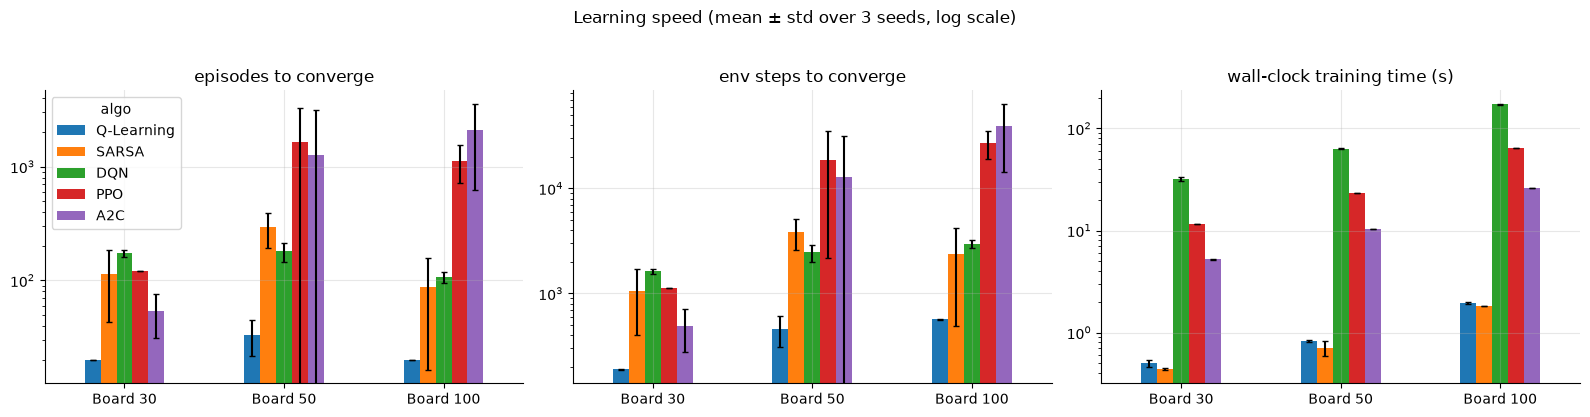

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, label, logy) in zip(axes, [("conv_ep", "episodes to converge", True),
                                         ("conv_steps", "env steps to converge", True),
                                         ("time", "wall-clock training time (s)", True)]):
    piv = RAW.groupby(["board", "algo"])[col].mean().unstack()[ALGOS].loc[list(BOARDS)]
    err = RAW.groupby(["board", "algo"])[col].std().unstack()[ALGOS].loc[list(BOARDS)]
    piv.plot.bar(ax=ax, yerr=err, color=[COLORS[a] for a in ALGOS], rot=0, capsize=2, legend=ax is axes[0])
    ax.set_yscale("log" if logy else "linear"); ax.set_title(label); ax.set_xlabel("")
plt.suptitle("Learning speed (mean ± std over 3 seeds, log scale)", y=1.03); plt.tight_layout(); plt.show()

### 6.2 Training curves
Curves are smoothed with a 100-episode moving average and averaged over the 3 seeds (shaded = ±1 std). The x-axis
is logarithmic because the DRL agents play many more (and, early on, shorter) episodes than the tabular agents.
Dashed black = optimal policy, dotted grey = random policy.

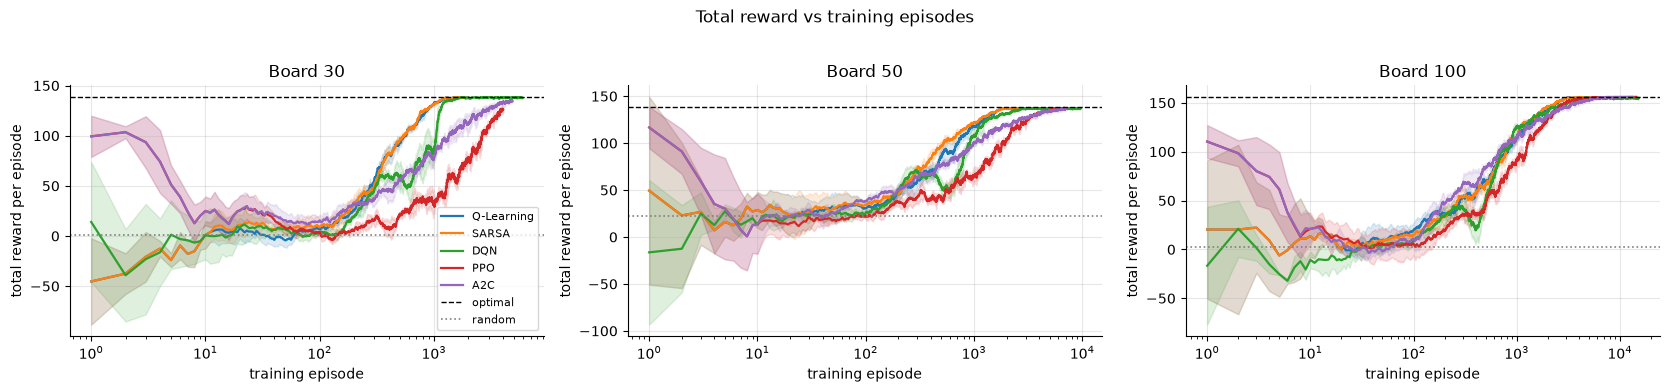

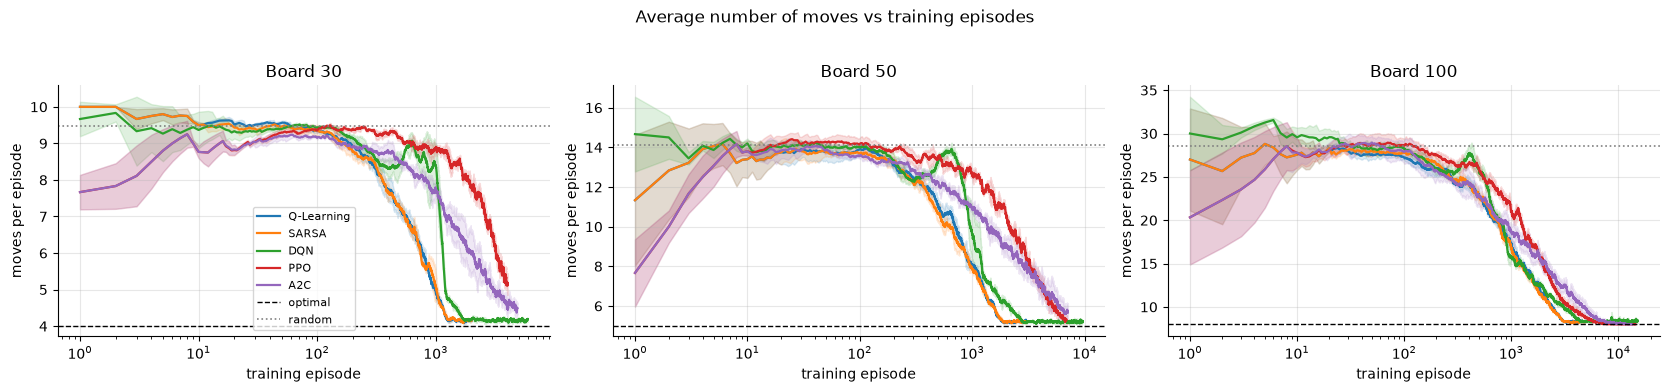

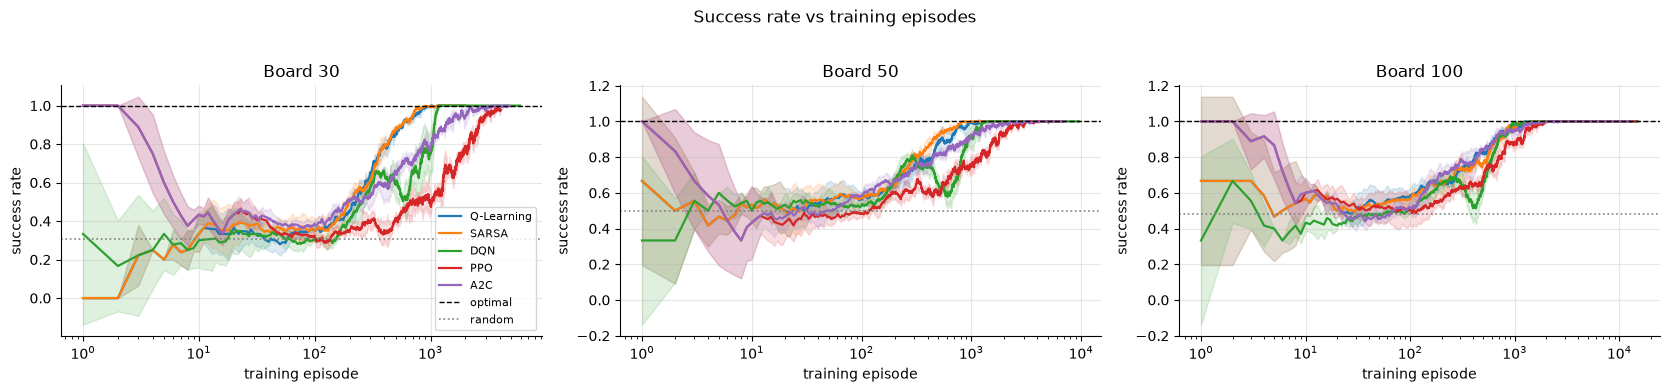

In [12]:
def smooth(x, w=100):
    return pd.Series(np.asarray(x, float)).rolling(w, min_periods=1).mean().to_numpy()


def mean_curve(logs, key, w=100):
    curves = [smooth(l[key], w) for l in logs]
    L = min(map(len, curves))
    arr = np.stack([c[:L] for c in curves])
    return np.arange(1, L + 1), arr.mean(0), arr.std(0)


def plot_training(results, boards, key, ylabel, algos=ALGOS, w=100, logx=True, refs=True, title=None):
    fig, axes = plt.subplots(1, len(boards), figsize=(5.6 * len(boards), 3.8), squeeze=False)
    for ax, bname in zip(axes[0], boards):
        for algo in algos:
            x, mu, sd = mean_curve([results[(bname, algo, s)] for s in SEEDS], key, w)
            ax.plot(x, mu, color=COLORS[algo], label=algo, lw=1.6)
            ax.fill_between(x, mu - sd, mu + sd, color=COLORS[algo], alpha=.15)
        if refs and bname in OPTIMAL:
            opt = {"reward": OPTIMAL[bname]["ret"], "moves": OPTIMAL[bname]["moves"], "success": 1.0}[key]
            rnd = {"reward": RANDOM[bname]["ret"], "moves": RANDOM[bname]["moves"], "success": RANDOM[bname]["success"]}[key]
            ax.axhline(opt, color="k", ls="--", lw=1, label="optimal")
            ax.axhline(rnd, color="grey", ls=":", lw=1.2, label="random")
        if logx:
            ax.set_xscale("log")
        ax.set_title(bname); ax.set_xlabel("training episode"); ax.set_ylabel(ylabel)
    axes[0][0].legend(fontsize=8)
    if title:
        fig.suptitle(title, y=1.02)
    plt.tight_layout(); plt.show()


plot_training(CORE, BOARDS, "reward", "total reward per episode", title="Total reward vs training episodes")
plot_training(CORE, BOARDS, "moves", "moves per episode", title="Average number of moves vs training episodes")
plot_training(CORE, BOARDS, "success", "success rate", title="Success rate vs training episodes")

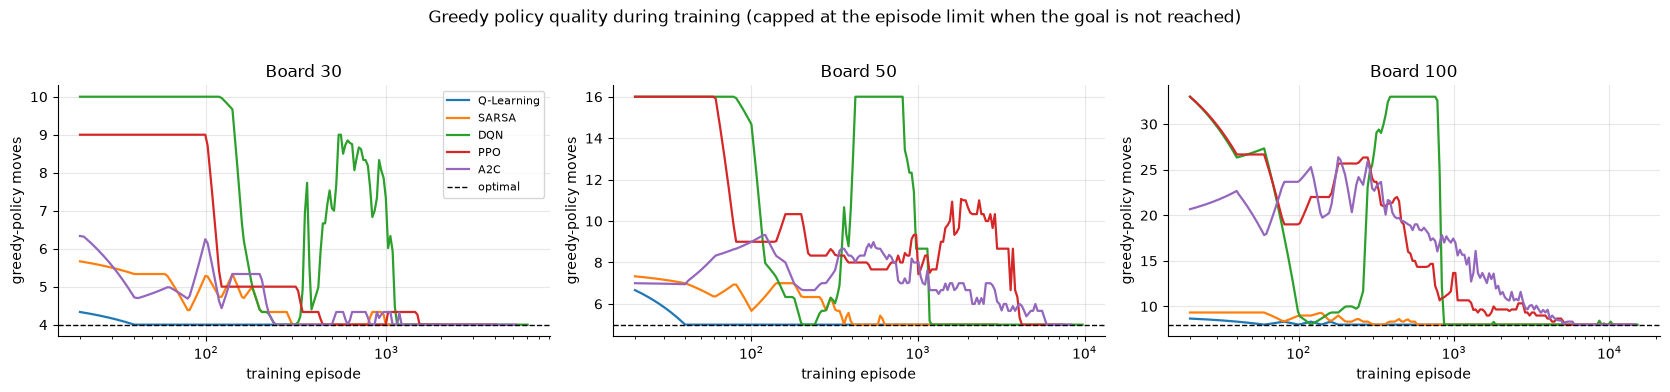

In [13]:
def plot_greedy(results, boards, algos=ALGOS):
    # Moves of the greedy policy (evaluated every 20 episodes) against training episodes.
    fig, axes = plt.subplots(1, len(boards), figsize=(5.6 * len(boards), 3.8), squeeze=False)
    for ax, bname in zip(axes[0], boards):
        grid = np.unique(np.geomspace(20, max(results[(bname, a, s)]["eval"][-1][0] for a in algos for s in SEEDS), 200).astype(int))
        for algo in algos:
            ys = []
            for s in SEEDS:
                ev = np.array(results[(bname, algo, s)]["eval"])
                y = np.interp(grid, ev[:, 0], ev[:, 2], right=np.nan)
                ys.append(y)
            ax.plot(grid, np.nanmean(ys, 0), color=COLORS[algo], label=algo, lw=1.6)
        ax.axhline(OPTIMAL[bname]["moves"], color="k", ls="--", lw=1, label="optimal")
        ax.set_xscale("log"); ax.set_title(bname); ax.set_xlabel("training episode"); ax.set_ylabel("greedy-policy moves")
    axes[0][0].legend(fontsize=8)
    fig.suptitle("Greedy policy quality during training (capped at the episode limit when the goal is not reached)", y=1.02)
    plt.tight_layout(); plt.show()


plot_greedy(CORE, BOARDS)

### 6.3 Q-Learning vs SARSA
First, the two tabular methods on the three boards (linear x-axis).

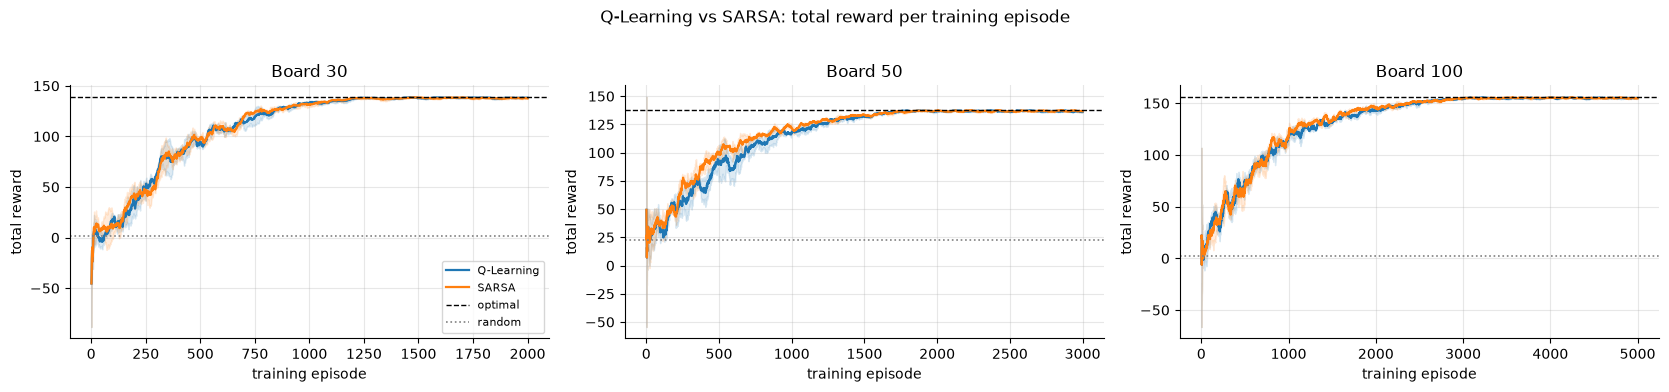

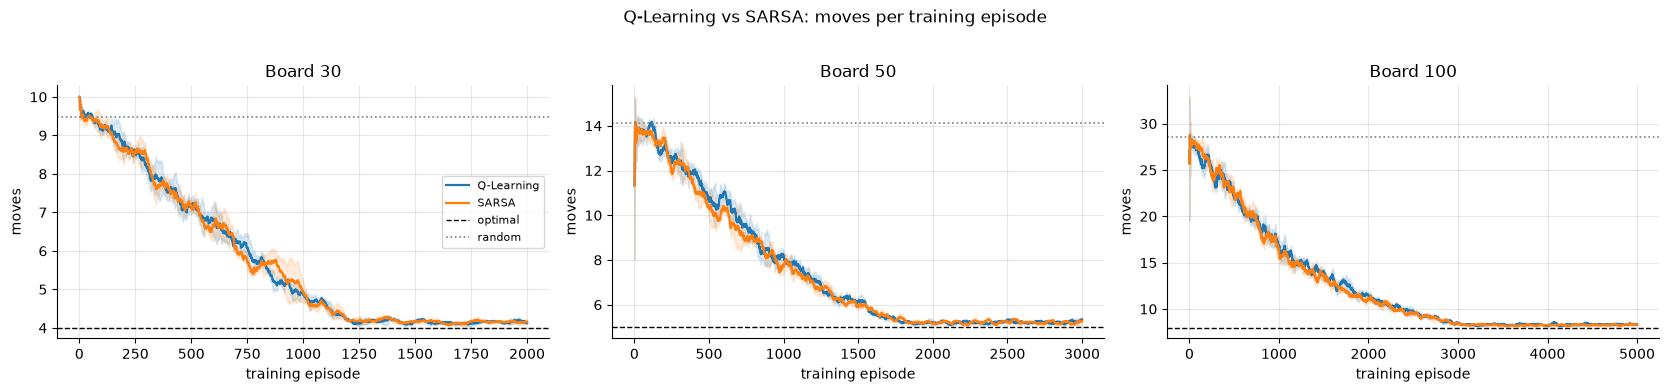

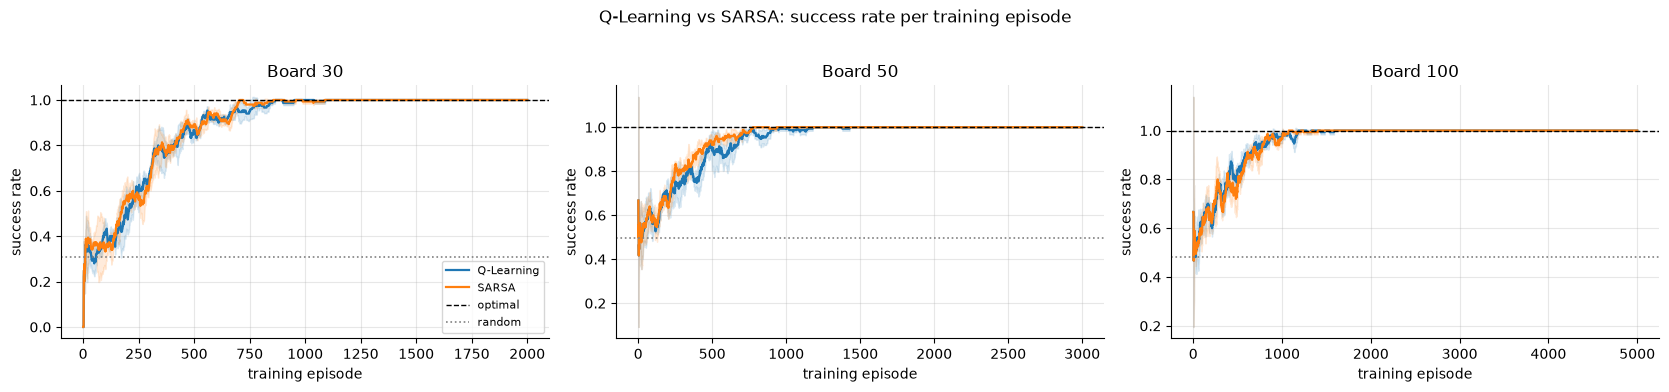

In [14]:
plot_training(CORE, BOARDS, "reward", "total reward", algos=["Q-Learning", "SARSA"], w=50, logx=False,
              title="Q-Learning vs SARSA: total reward per training episode")
plot_training(CORE, BOARDS, "moves", "moves", algos=["Q-Learning", "SARSA"], w=50, logx=False,
              title="Q-Learning vs SARSA: moves per training episode")
plot_training(CORE, BOARDS, "success", "success rate", algos=["Q-Learning", "SARSA"], w=50, logx=False,
              title="Q-Learning vs SARSA: success rate per training episode")

With ε decaying to 0.05 both methods end up with the same optimal route. Their difference shows up when exploration
**stays high**. Below both are trained on Board 100 with a **constant ε = 0.2** (5 seeds each). Each learned
policy is then executed ε-greedily (as during training) and greedily.

[cache] loaded results\fixed_eps.pkl


,online reward (last 1000 train eps),ε-greedy run: return,ε-greedy run: snakes hit / game,ε-greedy run: moves,greedy run: moves
algorithm,,,,,
Q-Learning,149.7 ± 1.0,149.7 ± 1.2,0.24 ± 0.02,10.0 ± 0.3,8.0 ± 0.0
SARSA,150.0 ± 0.4,150.0 ± 1.1,0.23 ± 0.03,10.1 ± 0.5,8.2 ± 0.4


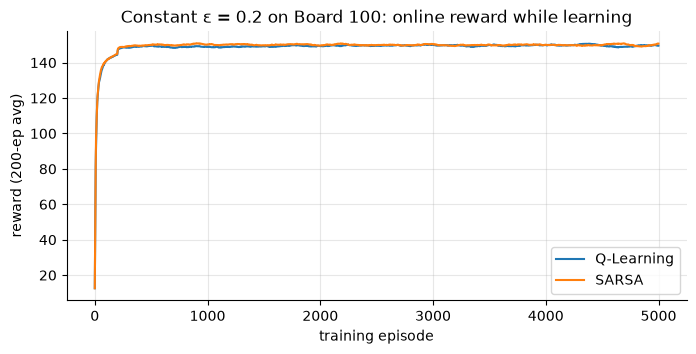

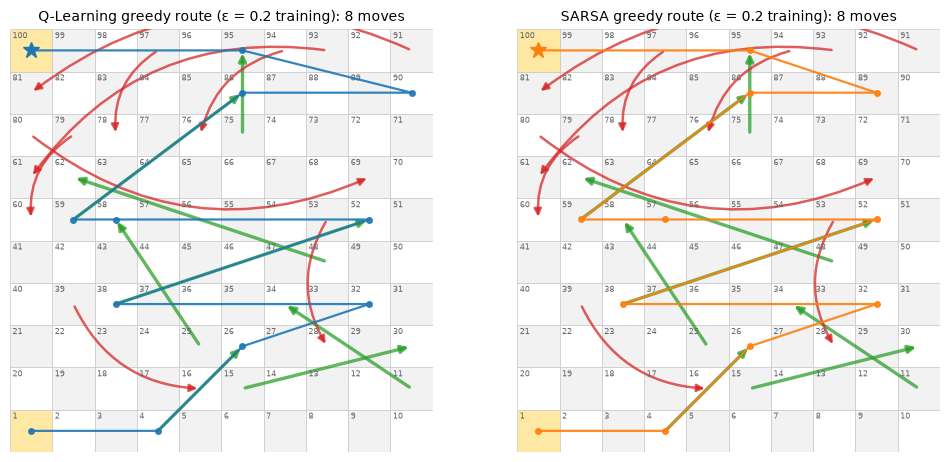

In [15]:
def run_fixed_eps():
    out = {}
    b = BOARDS["Board 100"]
    for algo in ("Q-Learning", "SARSA"):
        for seed in range(5):
            env = DiceBoardEnv(**b)
            ag = TabularAgent(env.n_states, 6, "qlearning" if algo == "Q-Learning" else "sarsa",
                              eps_start=0.2, eps_end=0.2, seed=seed)
            log = ag.train(env, 5000, seed=seed)
            ag.eps = 0.2
            noisy = evaluate(lambda e: ag.act(e.state_index()), DiceBoardEnv(**b), 2000)
            greedy = evaluate(ag.predict, DiceBoardEnv(**b), 1)
            out[(algo, seed)] = dict(log=log, noisy=noisy, greedy=greedy, Q=ag.Q.copy(),
                                     rollout=rollout(ag.predict, DiceBoardEnv(**b)))
    return out


FIXED = cached("fixed_eps", run_fixed_eps)
tbl = []
for algo in ("Q-Learning", "SARSA"):
    rs = [FIXED[(algo, s)] for s in range(5)]
    tbl.append({"algorithm": algo,
                "online reward (last 1000 train eps)": pm([np.mean(r["log"]["reward"][-1000:]) for r in rs]),
                "ε-greedy run: return": pm([r["noisy"]["ret"] for r in rs]),
                "ε-greedy run: snakes hit / game": pm([r["noisy"]["snakes"] for r in rs], 2),
                "ε-greedy run: moves": pm([r["noisy"]["moves"] for r in rs]),
                "greedy run: moves": pm([r["greedy"]["moves"] for r in rs])})
display(pd.DataFrame(tbl).set_index("algorithm"))

fig, ax = plt.subplots(figsize=(8, 3.5))
for algo in ("Q-Learning", "SARSA"):
    arr = np.stack([smooth(FIXED[(algo, s)]["log"]["reward"], 200) for s in range(5)])
    ax.plot(arr.mean(0), color=COLORS[algo], label=algo)
ax.set_xlabel("training episode"); ax.set_ylabel("reward (200-ep avg)"); ax.legend()
ax.set_title("Constant ε = 0.2 on Board 100: online reward while learning"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, algo in zip(axes, ("Q-Learning", "SARSA")):
    ro = FIXED[(algo, 0)]["rollout"]
    draw_board(BOARDS["Board 100"], ax, ro["squares"], f"{algo} greedy route (ε = 0.2 training): {ro['moves']} moves",
               COLORS[algo])
plt.show()

## 7. Demonstration: before, during and after training

### 7.1 Before training (random policy)

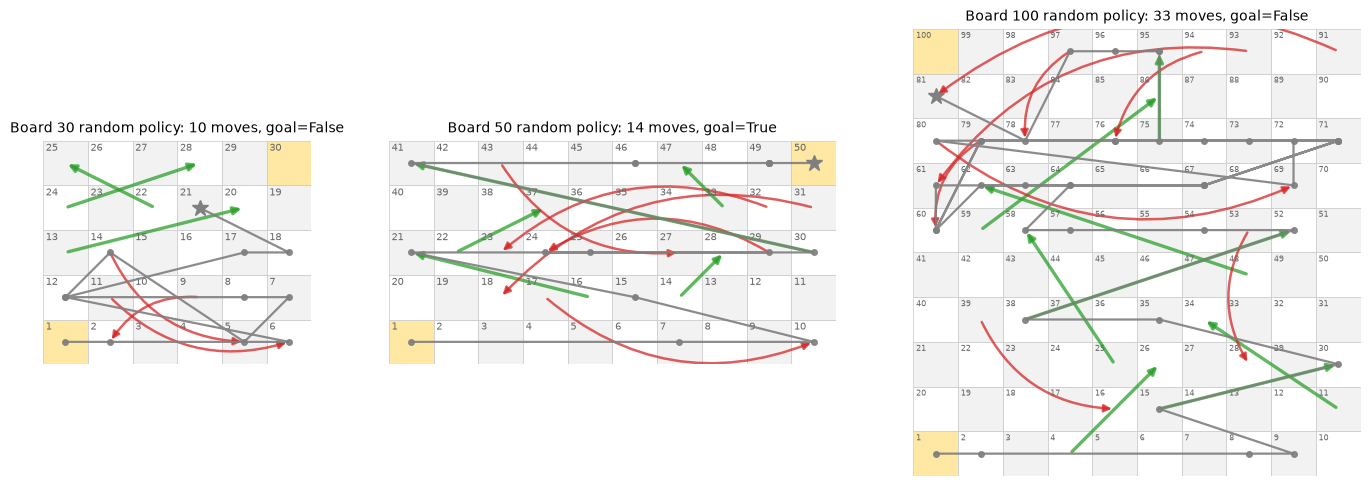

Random policy, Board 50: 14 moves, return +53, reached goal: True
   1-[6]->7  7-[3]->10  10-[5]->15  15-[6]->21  21-[4]->25  25-[4]->24(snake)  24-[6]->41(ladder)  41-[5]->46  46-[5]->46(invalid)  46-[3]->49  49-[2]->49(invalid)  49-[6]->49(invalid)  49-[2]->49(invalid)  49-[1]->50(goal)


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [6, 10, 10]})
for ax, bname in zip(axes, BOARDS):
    ro = RANDOM[bname]["rollout"]
    draw_board(BOARDS[bname], ax, ro["squares"], f"{bname} random policy: {ro['moves']} moves, goal={ro['success']}",
               "#7f7f7f")
plt.show()
show_trace(RANDOM["Board 50"]["rollout"], "Random policy, Board 50")

### 7.2 During training
Q-Learning on Board 50: the greedy route according to the Q-table after a growing number of episodes.

[cache] loaded results\snapshots.pkl


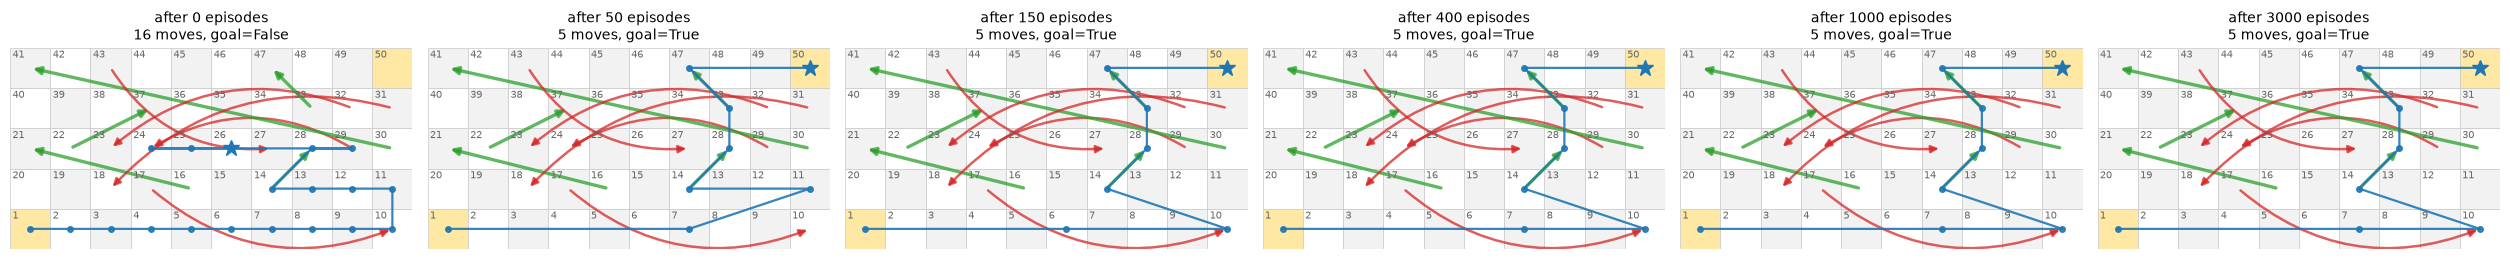

In [17]:
SNAPS = [0, 50, 150, 400, 1000, 3000]
snap_log = cached("snapshots", lambda: train_any("Q-Learning", BOARDS["Board 50"], 0, 3000, None, eval_every=0,
                                                 snapshots=SNAPS)[0])
fig, axes = plt.subplots(1, len(SNAPS), figsize=(4.2 * len(SNAPS), 4.4))
for ax, ep in zip(axes, SNAPS):
    ro = rollout(q_policy(snap_log["snapshots"][ep]), DiceBoardEnv(**BOARDS["Board 50"]))
    draw_board(BOARDS["Board 50"], ax, ro["squares"], f"after {ep} episodes\n{ro['moves']} moves, goal={ro['success']}")
plt.tight_layout(); plt.show()

### 7.3 After training
The learned greedy route of every algorithm (seed 0) on Board 100, next to the BFS shortest path.

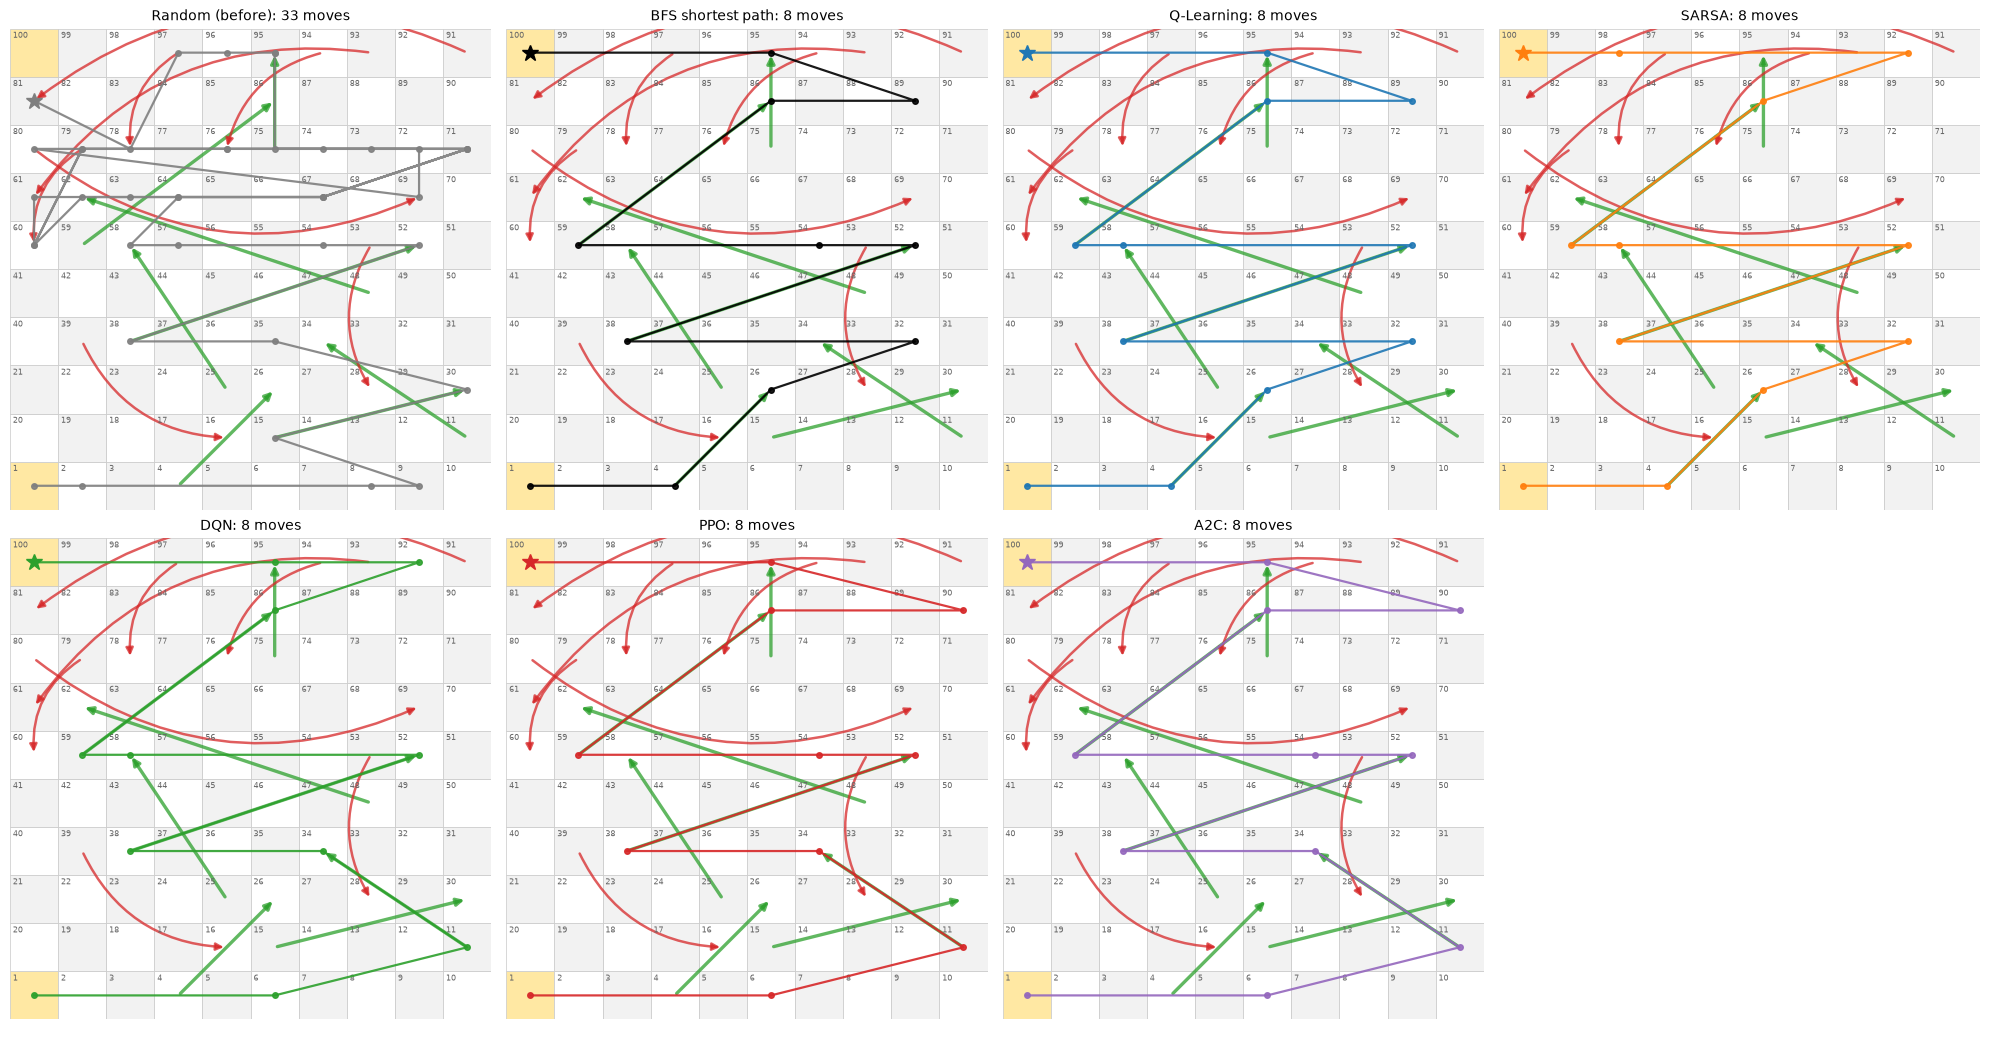

Q-Learning: 8 moves, return +156, reached goal: True
   1-[3]->26(ladder)  26-[6]->32  32-[6]->52(ladder)  52-[6]->58  58-[1]->86(ladder)  86-[3]->89  89-[6]->95  95-[5]->100(goal)
SARSA     : 8 moves, return +156, reached goal: True
   1-[3]->26(ladder)  26-[6]->32  32-[6]->52(ladder)  52-[6]->58  58-[1]->86(ladder)  86-[6]->92  92-[6]->98  98-[2]->100(goal)
DQN       : 8 moves, return +156, reached goal: True
   1-[5]->6  6-[5]->34(ladder)  34-[4]->52(ladder)  52-[6]->58  58-[1]->86(ladder)  86-[6]->92  92-[3]->95  95-[5]->100(goal)
PPO       : 8 moves, return +156, reached goal: True
   1-[5]->6  6-[5]->34(ladder)  34-[4]->52(ladder)  52-[2]->54  54-[5]->86(ladder)  86-[4]->90  90-[5]->95  95-[5]->100(goal)
A2C       : 8 moves, return +156, reached goal: True
   1-[5]->6  6-[5]->34(ladder)  34-[4]->52(ladder)  52-[2]->54  54-[5]->86(ladder)  86-[4]->90  90-[5]->95  95-[5]->100(goal)


In [18]:
b = "Board 100"
panels = [("Random (before)", RANDOM[b]["rollout"], "Random")]
bfs_squares = [1]
for p, d, q in OPTIMAL[b]["bfs_path"]:
    if p + d != q:
        bfs_squares.append(p + d)
    bfs_squares.append(q)
panels.append(("BFS shortest path", dict(squares=bfs_squares, moves=OPTIMAL[b]["bfs"], success=True), "Optimal"))
panels += [(a, CORE[(b, a, 0)]["rollout"], a) for a in ALGOS]
fig, axes = plt.subplots(2, 4, figsize=(20, 10.5))
for ax, (label, ro, c) in zip(axes.flat, panels):
    draw_board(BOARDS[b], ax, ro["squares"], f"{label}: {ro['moves']} moves", COLORS[c])
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()
for a in ALGOS:
    show_trace(CORE[(b, a, 0)]["rollout"], f"{a:10s}")

## 8. Random dice: Challenges 1, 2 and 4

### 8.1 Challenge 1 / Environment B: stochastic transitions

Now the environment rolls the die. The dice outcome is an **environment transition**, not an action. If the agent
had **no** decision at all, the game would be a Markov chain and there would be nothing to learn. So I give the agent
one meaningful decision:

> After seeing the roll $d$, the agent chooses **move** ($p \to \text{jump}(p+d)$) or **stay** (skip the turn, −1).

**Revised MDP.** State $=(p,d)$, giving $6N$ states. Actions are {stay, move}. The transition is now stochastic
because the next roll is $d' \sim U\{1,\dots,6\}$. An overshooting move is still invalid (−10, stay on $p$). The
reward is R-v0 (plus −1 for staying). Staying is useful when the roll would land on a snake head or
overshoot the goal. The objective is maximum expected return. I report **win probability** (goal within $4N$
moves), **expected game length**, return, and snakes hit per game.

Baselines: the classic game (*always move*), a random stay/move policy, and the exact optimum from value iteration
on the $6N$-state model. Board 50 is used; each algorithm gets 20k episodes (tabular) or 200k steps (DRL), 3 seeds.
An extra row, **DQN (no reward scaling)**, shows the failure that the reward scaling of Section 4.4 fixes.

In [19]:
RD_BOARD = "Board 50"
RD = dict(BOARDS[RD_BOARD], random_dice=True, max_steps=4 * BOARDS[RD_BOARD]["n"])
RD_EVAL = 3000


def run_random_dice():
    out = {}
    for algo in ALGOS:
        for seed in SEEDS:
            log, policy = train_any(algo, RD, seed, 20_000, 200_000, eval_every=0, tag="RandomDice")
            log["final"] = evaluate(policy, DiceBoardEnv(**RD), RD_EVAL, seed=77_000)
            out[(RD_BOARD, algo, seed)] = log
            print(f"{algo:10s} seed {seed}: {log['time']:6.1f}s  return={log['final']['ret']:.1f}  "
                  f"moves={log['final']['moves']:.1f}  snakes={log['final']['snakes']:.2f}")
    for seed in SEEDS:                                      # ablation: DQN without reward scaling
        log, policy = train_any("DQN", RD, seed, None, 200_000, eval_every=0, dqn_reward_scale=1.0)
        log["final"] = evaluate(policy, DiceBoardEnv(**RD), RD_EVAL, seed=77_000)
        out[(RD_BOARD, "DQN (no reward scaling)", seed)] = log
        print(f"DQN unscaled seed {seed}: return={log['final']['ret']:.1f}  win={log['final']['success']:.0%}")
    return out


RDRES = cached("random_dice", run_random_dice)

env_rd = DiceBoardEnv(**RD)
Q_RD = value_iteration(env_rd)
base = {"Optimal (VI)": evaluate(q_policy(Q_RD), DiceBoardEnv(**RD), RD_EVAL, seed=77_000),
        "Always move (classic game)": evaluate(lambda e: 1, DiceBoardEnv(**RD), RD_EVAL, seed=77_000),
        "Random stay/move": evaluate(random_policy, DiceBoardEnv(**RD), RD_EVAL, seed=77_000)}
rows = [{"policy": k, "win %": f"{100 * v['success']:.1f}", "expected length": f"{v['moves']:.2f}",
         "avg return": f"{v['ret']:.1f}", "snakes / game": f"{v['snakes']:.2f}", "stays / game": f"{v['stays']:.2f}"}
        for k, v in base.items()]
for algo in ALGOS + ["DQN (no reward scaling)"]:
    fs = [RDRES[(RD_BOARD, algo, s)]["final"] for s in SEEDS]
    rows.append({"policy": algo, "win %": pm([100 * f["success"] for f in fs]),
                 "expected length": pm([f["moves"] for f in fs], 2), "avg return": pm([f["ret"] for f in fs]),
                 "snakes / game": pm([f["snakes"] for f in fs], 2), "stays / game": pm([f["stays"] for f in fs], 2),
                 "train time (s)": pm([RDRES[(RD_BOARD, algo, s)]["time"] for s in SEEDS])})
RD_TABLE = pd.DataFrame(rows).fillna("").set_index("policy")
RD_TABLE.to_csv(os.path.join(RESULTS_DIR, "random_dice_summary.csv"))
display(RD_TABLE)

[cache] loaded results\random_dice.pkl


,win %,expected length,avg return,snakes / game,stays / game,train time (s)
policy,,,,,,
Optimal (VI),100.0,16.42,126.6,0.02,9.13,
Always move (classic game),100.0,18.13,47.3,1.90,0.00,
Random stay/move,100.0,36.41,28.6,1.93,18.24,
Q-Learning,100.0 ± 0.0,16.46 ± 0.14,126.6 ± 0.1,0.01 ± 0.01,7.86 ± 0.07,13.9 ± 0.1
SARSA,100.0 ± 0.0,16.95 ± 0.05,126.1 ± 0.1,0.01 ± 0.02,9.27 ± 0.46,13.1 ± 0.0
DQN,100.0 ± 0.0,16.52 ± 0.12,126.5 ± 0.1,0.02 ± 0.00,8.48 ± 0.40,230.0 ± 1.1
PPO,100.0 ± 0.0,18.28 ± 0.06,105.4 ± 4.3,0.56 ± 0.12,7.35 ± 1.26,73.5 ± 0.3
A2C,100.0 ± 0.0,18.16 ± 0.38,101.6 ± 6.6,0.61 ± 0.22,6.78 ± 1.73,31.1 ± 0.2
DQN (no reward scaling),60.8 ± 26.3,91.42 ± 46.43,3.6 ± 79.3,0.13 ± 0.11,85.45 ± 47.90,203.1 ± 3.8


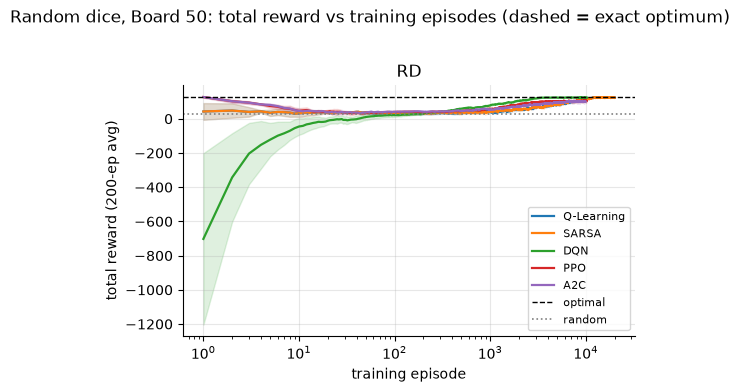

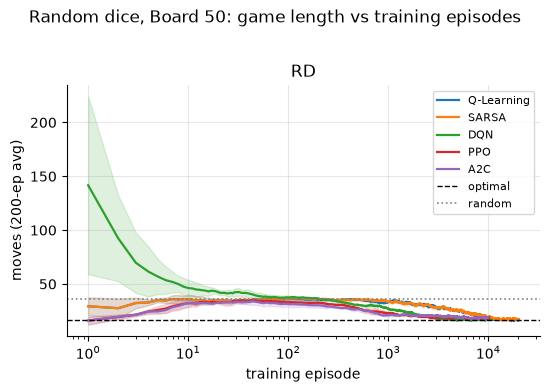

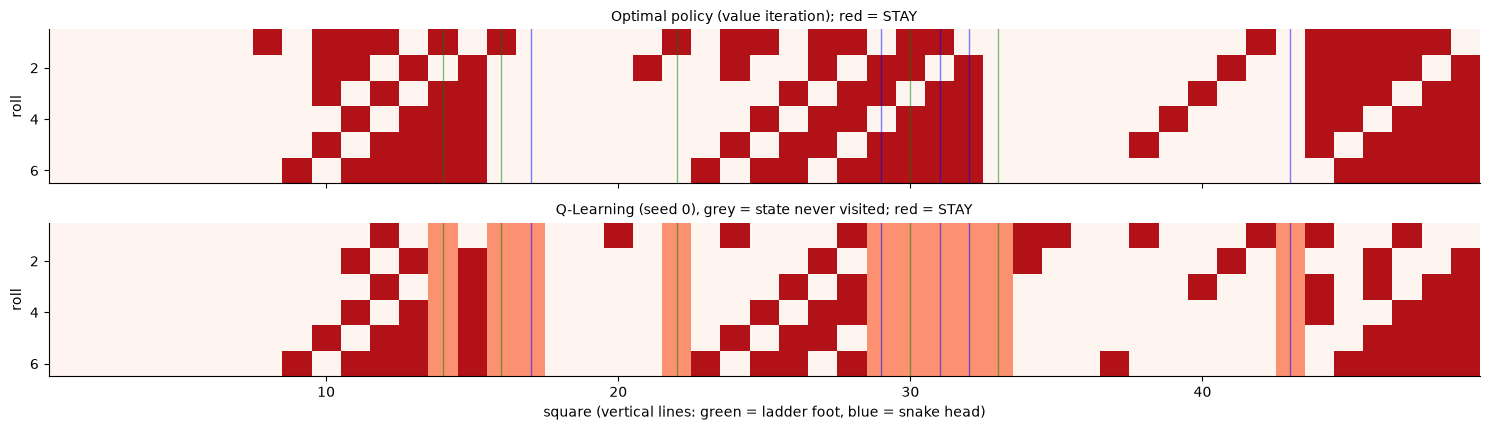

Q-Learning visited 80% of the (square, roll) states and agrees with the optimal stay/move decision in 89% of them


In [20]:
OPTIMAL["RD"], RANDOM["RD"] = dict(ret=base["Optimal (VI)"]["ret"], moves=base["Optimal (VI)"]["moves"]), \
    dict(ret=base["Random stay/move"]["ret"], moves=base["Random stay/move"]["moves"], success=base["Random stay/move"]["success"])
RD_KEYED = {("RD", a, s): RDRES[(RD_BOARD, a, s)] for a in ALGOS for s in SEEDS}
plot_training(RD_KEYED, ["RD"], "reward", "total reward (200-ep avg)", w=200,
              title="Random dice, Board 50: total reward vs training episodes (dashed = exact optimum)")
plot_training(RD_KEYED, ["RD"], "moves", "moves (200-ep avg)", w=200,
              title="Random dice, Board 50: game length vs training episodes")

# where does the agent choose to stay?  rows = roll, columns = square
n = RD["n"]
Q_QL = RDRES[(RD_BOARD, "Q-Learning", 0)]["Q"]
opt_stay = (Q_RD.argmax(1) == 0).astype(float)
ql_stay = np.where(Q_QL[:, 0] == Q_QL[:, 1], 0.45, (Q_QL.argmax(1) == 0).astype(float))   # tie = never visited
fig, axes = plt.subplots(2, 1, figsize=(15, 4.4), sharex=True)
for ax, M, t in zip(axes, (opt_stay, ql_stay), ("Optimal policy (value iteration)",
                                                "Q-Learning (seed 0), grey = state never visited")):
    ax.imshow(M.reshape(n, 6).T[:, :-1], aspect="auto", cmap="Reds", vmin=0, vmax=1.2, extent=[0.5, n - 0.5, 6.5, 0.5])
    for s, e in RD["jumps"].items():
        ax.axvline(s, color="green" if e > s else "blue", lw=1, alpha=.5)
    ax.set_ylabel("roll"); ax.set_title(f"{t}; red = STAY", fontsize=10); ax.grid(False)
axes[1].set_xlabel("square (vertical lines: green = ladder foot, blue = snake head)")
plt.tight_layout(); plt.show()
visited = (Q_QL[:, 0] != Q_QL[:, 1])[:-6]
agree = (Q_RD.argmax(1) == Q_QL.argmax(1))[:-6][visited].mean()
print(f"Q-Learning visited {visited.mean():.0%} of the (square, roll) states and agrees with the optimal "
      f"stay/move decision in {agree:.0%} of them")

### 8.2 Challenge 2: one chance to avoid a snake

**Design.** On the random-dice game the agent could already dodge every snake with the *stay* action, so a one-time
snake-avoid ability would be pointless there. Here the agent **must move every turn**, as in the classic game. In
exchange it owns **one shield**:

> After seeing the roll, the agent chooses **move** or **move and use the shield**. The shield is spent only if the
> move would land on a snake head; that snake is then ignored (the move counts as a normal square, −1). If the move
> does not hit a snake, the shield is kept.

So the real decision is *which snake to spend the shield on*: use it now on a short snake, or save it for a longer one
later.

**Revised MDP.** State $=(p, d, k)$ with $k\in\{0,1\}$ the **remaining ability**, added to the state representation,
for $2 \times 6N$ states. Actions are {move, move + shield}. The reward is R-v0. Board 100 is
used because its 8 snakes have very different lengths (10 to 32 squares). Budgets: 20k episodes (tabular) or 200k
steps (DRL), 3 seeds. Baselines: never use the shield (the classic game), use it on the first snake, and the exact
optimum from value iteration on the $12N$-state model.

In [21]:
SH = dict(BOARDS["Board 100"], shield=True, max_steps=400)
SH_EVAL = 3000
SNAKES_100 = {h: t for h, t in BOARDS["Board 100"]["jumps"].items() if t < h}
gym_check_env(DiceBoardEnv(**SH), skip_render_check=True)


def shield_decisions(policy):
    # For each snake: share of the (square, roll) situations that would hit it in which the policy spends the shield.
    env = DiceBoardEnv(**SH); env.reset(seed=0)
    out = {}
    for h in SNAKES_100:
        uses = []
        for d in range(1, 7):
            p = h - d
            if p >= 1 and p not in SH["jumps"]:            # nobody ever rests on a snake head / ladder foot
                env.pos, env.roll, env.shield_left = p, d, 1
                uses.append(policy(env))
        out[h] = float(np.mean(uses))
    return out


SH_DQN_SCALE = 0.01   # see the note below the tables: x0.1 is not enough on this task


def run_shield(algos=ALGOS, dqn_scale=DQN_REWARD_SCALE):
    out = {}
    for algo in algos:
        for seed in SEEDS:
            log, policy = train_any(algo, SH, seed, 20_000, 200_000, eval_every=0, dqn_reward_scale=dqn_scale)
            log["final"] = evaluate(policy, DiceBoardEnv(**SH), SH_EVAL, seed=88_000)
            log["decisions"] = shield_decisions(policy)
            out[("SH", algo, seed)] = log
            print(f"{algo:10s} seed {seed}: {log['time']:6.1f}s  return={log['final']['ret']:.1f}  "
                  f"snakes={log['final']['snakes']:.2f}  shield used={log['final']['shielded']:.2f}")
    return out


SHRES = cached("shield", run_shield)                                     # all algorithms; DQN with rewards x 0.1
SHDQN = cached("shield_dqn001", lambda: run_shield(["DQN"], SH_DQN_SCALE))  # DQN with rewards x 0.01
SH_RUNS = {**{a: [SHRES[("SH", a, s)] for s in SEEDS] for a in ALGOS},
           "DQN": [SHDQN[("SH", "DQN", s)] for s in SEEDS],
           "DQN (rewards x 0.1, ablation)": [SHRES[("SH", "DQN", s)] for s in SEEDS]}

Q_SH = value_iteration(DiceBoardEnv(**SH))
sh_base = {"Optimal (VI)": q_policy(Q_SH), "Never use the shield (classic game)": lambda e: 0,
           "Use it on the first snake": lambda e: 1}
rows = []
for name, pol in sh_base.items():
    f = evaluate(pol, DiceBoardEnv(**SH), SH_EVAL, seed=88_000)
    rows.append({"policy": name, "avg return": f"{f['ret']:.1f}", "expected length": f"{f['moves']:.2f}",
                 "snakes hit / game": f"{f['snakes']:.2f}", "shield used %": f"{100 * f['shielded']:.1f}",
                 "squares saved by shield": f"{f['saved']:.1f}"})
for algo, logs in SH_RUNS.items():
    fs = [l["final"] for l in logs]
    rows.append({"policy": algo, "avg return": pm([f["ret"] for f in fs]), "expected length": pm([f["moves"] for f in fs], 2),
                 "snakes hit / game": pm([f["snakes"] for f in fs], 2), "shield used %": pm([100 * f["shielded"] for f in fs]),
                 "squares saved by shield": pm([f["saved"] for f in fs]),
                 "train time (s)": pm([l["time"] for l in logs])})
SH_TABLE = pd.DataFrame(rows).fillna("").set_index("policy")
SH_TABLE.to_csv(os.path.join(RESULTS_DIR, "shield_summary.csv"))
display(SH_TABLE)

dec = {"Optimal (VI)": shield_decisions(q_policy(Q_SH))}
for algo, logs in SH_RUNS.items():
    dec[algo] = {h: np.mean([l["decisions"][h] for l in logs]) for h in SNAKES_100}
DEC = pd.DataFrame(dec)
DEC.index = [f"{h} -> {t} (length {h - t})" for h, t in SNAKES_100.items()]
print("Share of situations in which the shield is spent on each snake (1 = always, 0 = saves it):")
display(DEC.round(2))

[cache] loaded results\shield.pkl
[cache] loaded results\shield_dqn001.pkl


,avg return,expected length,snakes hit / game,shield used %,squares saved by shield,train time (s)
policy,,,,,,
Optimal (VI),45.9,29.94,1.72,54.4,12.6,
Never use the shield (classic game),10.0,38.25,3.59,0.0,0.0,
Use it on the first snake,29.1,33.58,2.32,82.8,16.7,
Q-Learning,45.1 ± 0.3,30.32 ± 0.09,1.83 ± 0.01,52.7 ± 0.6,10.7 ± 0.0,22.4 ± 0.2
SARSA,42.7 ± 1.5,30.59 ± 0.30,1.87 ± 0.04,59.9 ± 1.4,13.2 ± 0.4,20.9 ± 0.3
DQN,44.5 ± 0.2,30.23 ± 0.32,1.79 ± 0.02,58.6 ± 1.7,12.6 ± 1.1,157.0 ± 26.5
PPO,30.7 ± 1.3,33.31 ± 0.25,2.29 ± 0.03,80.5 ± 1.8,16.3 ± 0.4,30.3 ± 0.2
A2C,29.2 ± 0.2,33.52 ± 0.08,2.31 ± 0.01,82.5 ± 0.5,16.8 ± 0.0,20.2 ± 10.2
"DQN (rewards x 0.1, ablation)",10.7 ± 1.1,38.64 ± 0.30,3.37 ± 0.16,32.3 ± 23.0,3.4 ± 2.4,198.1 ± 18.4


Share of situations in which the shield is spent on each snake (1 = always, 0 = saves it):


,Optimal (VI),Q-Learning,SARSA,DQN,PPO,A2C,"DQN (rewards x 0.1, ablation)"
39 -> 16 (length 23),0.0,0.00,0.47,0.00,0.87,1.00,0.00
53 -> 28 (length 25),0.0,1.00,1.00,0.80,0.93,1.00,0.00
79 -> 60 (length 19),0.0,0.00,0.00,0.00,0.93,1.00,0.00
80 -> 69 (length 11),0.0,0.00,0.00,0.00,0.75,0.92,0.67
91 -> 81 (length 10),0.0,0.06,0.00,0.22,0.94,0.94,0.33
93 -> 61 (length 32),1.0,0.00,0.33,0.67,0.93,1.00,0.00
94 -> 76 (length 18),1.0,1.00,1.00,1.00,0.92,1.00,0.00
97 -> 78 (length 19),1.0,1.00,1.00,1.00,1.00,1.00,0.00


**Reading the decision table.** Each row is a snake, ordered by where it sits on the board. A value of 1 means
"spend the shield whenever a roll would hit this snake", and 0 means "take the hit and keep the shield for later".
Comparing a learned row with the *Optimal (VI)* column shows whether the agent learned the trade-off between the
length of a snake and the chance of meeting a worse one later.

**Why DQN needs rewards × 0.01 here.** With the ×0.1 scaling used everywhere else, DQN did no better than never
using the shield, and its shield decisions agreed with the optimum only about half of the time. The cause is SB3's
**Huber loss**, which is quadratic for errors below 1 but linear above. With random dice, one TD target can differ by
±20 (×0.1 = ±2) depending on whether the next roll hits a ladder or a snake. In the linear region the network fits
something closer to the **median** than the **mean** of these targets, a bias that matters exactly in the rare snake
states where the shield decision is made. Scaling rewards by 0.01 keeps the errors in the quadratic region
(equivalently, MSE loss), and DQN then reaches a return within a few points of the optimum. Learning longer, more
gradient updates, and extra "this roll hits a snake" features did **not** help (tested separately). The reward scale
is a per-task hyper-parameter: ×0.1 already reaches the optimum in the other DQN experiments.

### 8.3 Challenge 4: two players

**Design.** The agent races a **rule-based opponent** on Board 50. Both players use random dice, and each turn a
player may **stay** or **move**, as in Section 8.1. A random draw decides who starts. One interaction rule makes the
opponent matter:

> **Bump rule:** landing exactly on the square of the other player sends that player back to square 1.

**Revised MDP (from the agent's point of view).** State $=(p, d, q)$: own square, own roll and the **opponent's
square** $q$, for $6N^2 = 15\,000$ states. The opponent's turn is part of the (stochastic) environment transition.
Rewards are R-v0 for the agent's own moves, plus:
* **+20** for bumping the opponent (like a ladder) and **−20** for being bumped (like a snake);
* **−100** and the episode ends if the **opponent reaches the goal first**.

Winning (reaching the goal first) still gives +100.

**Two objectives.** In a race the real goal is to **win**, not to collect ladder bonuses. So every algorithm is
trained twice: (a) with the R-v0-based reward above, and (b) with a **win/lose-only reward**: +1 for winning, −1 for
losing, 0 otherwise. Reward (b) makes the return equal to (discounted) **probability of winning**, the third possible
objective next to "minimum rolls" and "maximum expected return".

**Opponents.** The *always-move* opponent plays the classic game. The *cautious* opponent stays when its roll would
hit a snake or overshoot, and always moves when it can bump the agent. All agents are trained against
*always-move* only. They are then tested against **both**, to see whether the policy transfers to an opponent it has
never met. Budgets: 30k episodes (tabular) or 200k steps (DRL), 3 seeds. Baselines: always move, the cautious rule
itself, and the **single-player optimum** of Section 8.1. That last policy plays perfectly for itself but ignores
the opponent.

[cache] loaded results\two_player.pkl
[cache] loaded results\two_player_win.pkl


Columns other than 'win % vs cautious' are measured against the always-move opponent.


,win % vs always-move,win % vs cautious,moves,bumps given,times bumped,snakes hit,stays / game,train time (s)
policy,,,,,,,,
Always move (classic game),47.9,42.2,15.5,0.65,0.69,1.48,0.00,
Cautious rule (same as the opponent),54.1,47.0,14.8,0.62,0.66,0.00,3.43,
Single-player optimum (ignores opponent),48.3,42.6,14.7,0.45,0.69,0.01,6.51,
Random stay/move,12.6,9.5,17.8,0.33,0.41,0.73,8.96,
Q-Learning (R-v0 reward),49.4 ± 0.3,41.1 ± 0.7,15.9 ± 0.0,0.73 ± 0.01,0.31 ± 0.00,0.04 ± 0.00,7.18 ± 0.08,5.8 ± 0.1
SARSA (R-v0 reward),50.3 ± 0.6,41.5 ± 0.5,15.9 ± 0.1,0.73 ± 0.00,0.30 ± 0.01,0.03 ± 0.00,7.06 ± 0.09,5.5 ± 0.1
DQN (R-v0 reward),50.0 ± 0.7,42.8 ± 0.2,15.9 ± 0.1,0.75 ± 0.01,0.48 ± 0.00,0.01 ± 0.01,7.78 ± 0.23,154.2 ± 82.6
PPO (R-v0 reward),48.1 ± 0.3,42.3 ± 0.1,15.5 ± 0.0,0.66 ± 0.01,0.66 ± 0.04,1.41 ± 0.10,0.26 ± 0.37,71.2 ± 27.7
A2C (R-v0 reward),48.1 ± 0.2,42.1 ± 0.2,15.6 ± 0.2,0.68 ± 0.04,0.65 ± 0.05,1.42 ± 0.08,0.37 ± 0.52,17.2 ± 2.8


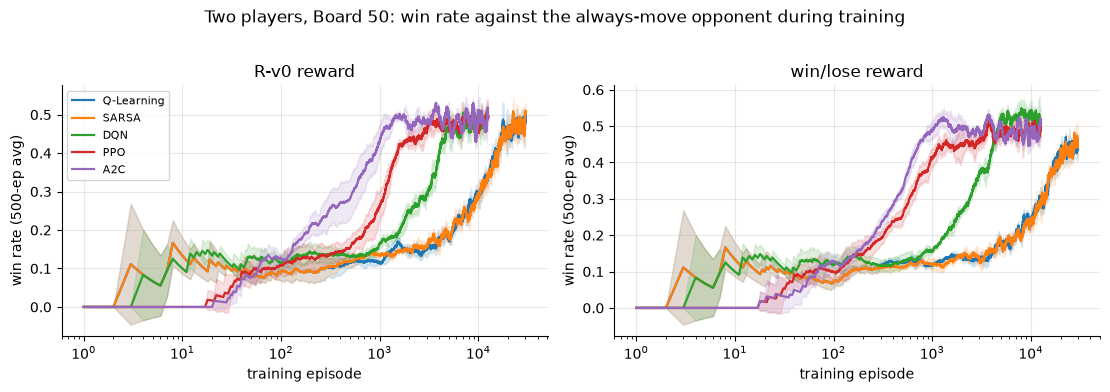

In [22]:
def opp_always_move(pos, roll, other, n, jumps):
    return 1


def opp_cautious(pos, roll, other, n, jumps):
    target = pos + roll
    if target > n:
        return 0                                           # would overshoot: stay
    if transition(pos, roll, n, jumps)[0] == other and other != n:
        return 1                                           # can bump the other player: move
    return 0 if (target in jumps and jumps[target] < target) else 1   # avoid snakes


OPPONENTS = {"always-move": opp_always_move, "cautious": opp_cautious}
BUMP_REWARD = 20.0


class TwoPlayerEnv(gym.Env):
    # Agent vs a rule-based opponent on one board. Random dice; action 0 = stay, 1 = move.
    # Bump rule: landing exactly on the other player's square sends that player back to square 1.
    metadata = {"render_modes": []}

    def __init__(self, n=50, jumps=None, opponent="always-move", max_steps=None, rewards=None, reward_scale=1.0,
                 win_only=False):
        super().__init__()
        self.n, self.jumps, self.opponent, self.win_only = n, dict(jumps or {}), opponent, win_only
        self.max_steps = max_steps or 4 * n
        self.rewards = {**REWARDS_V0, **(rewards or {})}
        self.reward_scale = reward_scale
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Box(0.0, 1.0, (2 * n + 6,), np.float32)
        self.pos = self.opp = self.roll = 1
        self.t = 0

    @property
    def n_states(self):
        return self.n * 6 * self.n

    def state_index(self):
        return ((self.pos - 1) * 6 + self.roll - 1) * self.n + self.opp - 1

    def _obs(self):
        o = np.zeros(self.observation_space.shape, np.float32)
        o[self.pos - 1] = 1.0; o[self.n + self.roll - 1] = 1.0; o[self.n + 6 + self.opp - 1] = 1.0
        return o

    def _move(self, me, other, roll, act):
        # One player's turn. Returns (me, other, reward for the mover, event, bumped_other).
        if act == 0:
            return me, other, self.rewards["stay"], "stay", False
        nxt, r, ev = transition(me, roll, self.n, self.jumps, self.rewards)
        if nxt == other and nxt != self.n:
            return nxt, 1, r, "bump", True
        return nxt, other, r, ev, False

    def _opponent_turn(self):
        d = int(self.np_random.integers(1, 7))
        a = OPPONENTS[self.opponent](self.opp, d, self.pos, self.n, self.jumps)
        self.opp, self.pos, _, _, bumped = self._move(self.opp, self.pos, d, a)
        return bumped

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.pos = self.opp = 1
        self.t = 0
        if self.np_random.random() < 0.5:                  # the opponent starts half of the games
            self._opponent_turn()
        self.roll = int(self.np_random.integers(1, 7))
        return self._obs(), {}

    def step(self, action):
        dice = self.roll
        self.pos, self.opp, reward, event, bump = self._move(self.pos, self.opp, dice, int(action))
        reward += BUMP_REWARD if bump else 0.0
        won, lost, bumped = self.pos == self.n, False, False
        if not won:
            bumped = self._opponent_turn()
            reward -= BUMP_REWARD if bumped else 0.0
            lost = self.opp == self.n
            reward -= self.rewards["goal"] if lost else 0.0
        self.roll = int(self.np_random.integers(1, 7))
        self.t += 1
        terminated = won or lost
        truncated = (not terminated) and self.t >= self.max_steps
        if self.win_only:                                  # objective = probability of winning the race
            reward = 1.0 if won else (-1.0 if lost else 0.0)
        info = {"event": event, "dice": dice, "is_success": won, "bumped": int(bumped), "lost": lost}
        return self._obs(), float(reward * self.reward_scale), terminated, truncated, info


TP = dict(env_cls=TwoPlayerEnv, n=50, jumps=BOARDS["Board 50"]["jumps"], opponent="always-move")
TP_EVAL = 3000
gym_check_env(make_env(**TP), skip_render_check=True)


def tp_eval(policy, opponent):
    return evaluate(policy, make_env(**{**TP, "opponent": opponent}), TP_EVAL, seed=99_000)


def run_two_player(env_kwargs, dqn_scale):
    out = {}
    for algo in ALGOS:
        for seed in SEEDS:
            log, policy = train_any(algo, env_kwargs, seed, 30_000, 200_000, eval_every=0, dqn_reward_scale=dqn_scale)
            log["final"] = {opp: tp_eval(policy, opp) for opp in OPPONENTS}
            out[("TP", algo, seed)] = log
            print(f"{algo:10s} seed {seed}: {log['time']:6.1f}s  win vs always-move={log['final']['always-move']['success']:.1%}"
                  f"  vs cautious={log['final']['cautious']['success']:.1%}")
    return out


# (a) the standard R-v0 reward + bump/lose terms;  (b) win/lose-only reward (+1 / -1), i.e. maximise P(win).
# The win/lose rewards are already of size 1, so DQN does not need the 0.1 scaling there.
TPRES = cached("two_player", lambda: run_two_player(TP, DQN_REWARD_SCALE))
TPWIN = cached("two_player_win", lambda: run_two_player({**TP, "win_only": True}, 1.0))

tp_base = {"Always move (classic game)": lambda e: 1,
           "Cautious rule (same as the opponent)": lambda e: opp_cautious(e.pos, e.roll, e.opp, e.n, e.jumps),
           "Single-player optimum (ignores opponent)": lambda e: int(np.argmax(Q_RD[(e.pos - 1) * 6 + e.roll - 1])),
           "Random stay/move": random_policy}
rows = []
for name, pol in tp_base.items():
    f = {opp: tp_eval(pol, opp) for opp in OPPONENTS}
    rows.append({"policy": name, "win % vs always-move": f"{100 * f['always-move']['success']:.1f}",
                 "win % vs cautious": f"{100 * f['cautious']['success']:.1f}",
                 "moves": f"{f['always-move']['moves']:.1f}", "bumps given": f"{f['always-move']['bumps']:.2f}",
                 "times bumped": f"{f['always-move']['bumped']:.2f}", "snakes hit": f"{f['always-move']['snakes']:.2f}",
                 "stays / game": f"{f['always-move']['stays']:.2f}"})
for res, tag in ((TPRES, "R-v0 reward"), (TPWIN, "win/lose reward")):
    for algo in ALGOS:
        fs = [res[("TP", algo, s)]["final"] for s in SEEDS]
        rows.append({"policy": f"{algo} ({tag})", "win % vs always-move": pm([100 * f["always-move"]["success"] for f in fs]),
                     "win % vs cautious": pm([100 * f["cautious"]["success"] for f in fs]),
                     "moves": pm([f["always-move"]["moves"] for f in fs]),
                     "bumps given": pm([f["always-move"]["bumps"] for f in fs], 2),
                     "times bumped": pm([f["always-move"]["bumped"] for f in fs], 2),
                     "snakes hit": pm([f["always-move"]["snakes"] for f in fs], 2),
                     "stays / game": pm([f["always-move"]["stays"] for f in fs], 2),
                     "train time (s)": pm([res[("TP", algo, s)]["time"] for s in SEEDS])})
TP_TABLE = pd.DataFrame(rows).fillna("").set_index("policy")
TP_TABLE.to_csv(os.path.join(RESULTS_DIR, "two_player_summary.csv"))
print("Columns other than 'win % vs cautious' are measured against the always-move opponent.")
display(TP_TABLE)

TP_KEYED = {(tag, a, s): res[("TP", a, s)] for res, tag in ((TPRES, "R-v0 reward"), (TPWIN, "win/lose reward"))
            for a in ALGOS for s in SEEDS}
plot_training(TP_KEYED, ["R-v0 reward", "win/lose reward"], "success", "win rate (500-ep avg)", w=500,
              title="Two players, Board 50: win rate against the always-move opponent during training")

## 9. Challenge 5: DQN vs tabular Q-Learning on larger boards

Boards of 200 squares (12 snakes + 12 ladders) and 400 squares (20 + 20), with episode limit $N/3$. Compared:

* **Tabular Q-Learning**, 8 000 episodes;
* **DQN, one-hot observation**, 150k steps (same network as before);
* **DQN, feature observation**: 26 numbers instead of $N$: normalised square, distance to goal and, for each dice
  value, "valid / ladder / snake / displacement". This shows what function approximation can do with a compact state.

The comparison uses **environment steps** on the x-axis, because a DQN step and a tabular step are the same amount of
experience. 3 seeds each.

[cache] loaded results\large_boards.pkl


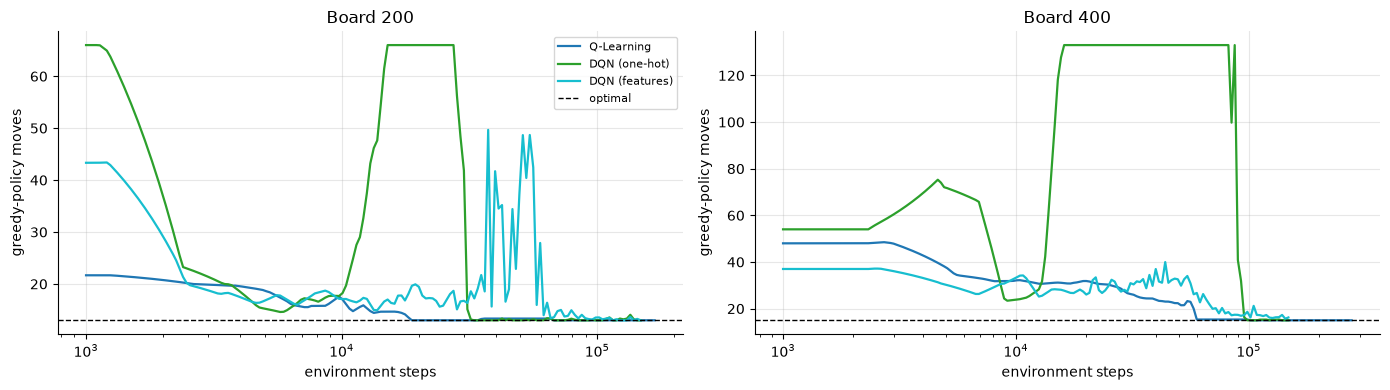

optimal moves final greedy moves  conv. env steps  \
board     method                                                              
Board 200 Q-Learning                 13         13.0 ± 0.0   14,316 ± 3,262   
          DQN (one-hot)              13         13.0 ± 0.0     30,778 ± 253   
          DQN (features)             13         13.0 ± 0.0  53,461 ± 16,078   
Board 400 Q-Learning                 15         15.0 ± 0.0   58,250 ± 1,504   
          DQN (one-hot)              15         15.0 ± 0.0   92,114 ± 2,875   
          DQN (features)             15         16.0 ± 0.8   99,916 ± 7,541   

                         train time (s)  
board     method                         
Board 200 Q-Learning          4.7 ± 0.2  
          DQN (one-hot)     194.7 ± 0.6  
          DQN (features)   133.7 ± 26.2  
Board 400 Q-Learning          2.2 ± 0.1  
          DQN (one-hot)      87.9 ± 6.8  
          DQN (features)     61.7 ± 2.3

In [23]:
LARGE = {"Board 200": dict(n=200, jumps=generate_board(200, 12, 12, seed=4), max_steps=200 // 3),
         "Board 400": dict(n=400, jumps=generate_board(400, 20, 20, seed=5), max_steps=400 // 3)}
LARGE_ALGOS = {"Q-Learning": ("Q-Learning", {}), "DQN (one-hot)": ("DQN", {}), "DQN (features)": ("DQN", {"obs_mode": "features"})}
COLORS.update({"DQN (one-hot)": "#2ca02c", "DQN (features)": "#17becf"})


def run_large():
    out = {}
    for bname, board in LARGE.items():
        for label, (algo, extra) in LARGE_ALGOS.items():
            for seed in SEEDS:
                kw = {**board, **extra}
                log, policy = train_any(algo, kw, seed, 8_000, 150_000, eval_every=25)
                log["final"] = evaluate(policy, DiceBoardEnv(**kw), 1)
                out[(bname, label, seed)] = log
                print(f"{bname} {label:15s} seed {seed}: {log['time']:6.1f}s  greedy moves={log['final']['moves']:.0f}")
    return out


LRES = cached("large_boards", run_large)

rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (bname, board) in zip(axes, LARGE.items()):
    opt = rollout(q_policy(value_iteration(DiceBoardEnv(**board))), DiceBoardEnv(**board))["moves"]
    grid = np.geomspace(1_000, 500_000, 200)
    for label in LARGE_ALGOS:
        logs = [LRES[(bname, label, s)] for s in SEEDS]
        conv = np.array([convergence(l, opt) for l in logs], float)
        ys = []
        for l in logs:
            ev = np.array(l["eval"]); steps = np.cumsum(l["moves"])[ev[:, 0].astype(int) - 1]
            ys.append(np.interp(grid, steps, ev[:, 2], right=np.nan))
        ax.plot(grid, np.nanmean(ys, 0), label=label, color=COLORS[label], lw=1.6)
        rows.append({"board": bname, "method": label, "optimal moves": opt,
                     "final greedy moves": pm([l["final"]["moves"] for l in logs]),
                     "conv. env steps": pm(conv[:, 1], 0), "train time (s)": pm([l["time"] for l in logs])})
    ax.axhline(opt, color="k", ls="--", lw=1, label="optimal")
    ax.set_xscale("log"); ax.set_xlabel("environment steps"); ax.set_ylabel("greedy-policy moves"); ax.set_title(bname)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
LARGE_TABLE = pd.DataFrame(rows).set_index(["board", "method"])
display(LARGE_TABLE)

## 10. Challenge 3 / Environment C: dynamic board

At **every episode** the snakes and ladders are placed again at random (50 squares, 5 snakes, 5 ladders). The agent
cannot memorise a route, so it has to learn a **general rule** from what it can see. Two kinds of agent are compared:

* **Position-only agents**: tabular Q-Learning whose state is just the square. They cannot see the board, so the best
  they can learn is a policy that is good *on average*. Also included is the Q-Learning policy trained on the fixed
  Board 50 (Section 5) and then dropped onto new boards, to test whether a memorised route generalises.
* **Feature-based DRL agents** (DQN, PPO, A2C) with the 26-feature observation of Section 9. They see only what a
  player sees within one roll: for each dice value, whether the move is valid and whether it lands on a ladder or
  snake, and how far it carries. This is a **limited-information** setting, because jumps further ahead are invisible.

References: a random policy, a hand-written **greedy rule** (always take the dice value whose landing square, after
any jump, is furthest ahead), and **BFS with full knowledge of each board** (the optimal number of rolls).
Every policy is tested on the same **300 unseen boards**. Budgets: 5 000 episodes (tabular) or 150k steps (DRL), 3 seeds.

[cache] loaded results\dynamic_board.pkl


,win %,avg moves,avg return,moves / BFS (won games),optimal games %,train time (s)
policy,,,,,,
Random policy,43.3,14.53,13.3,2.44,0.0,
Greedy rule (hand-written),100.0,5.39,146.0,1.02,88.7,
Q-Learning trained on fixed Board 50,33.7,14.01,-24.2,1.92,1.3,
Q-Learning (position only),51.2 ± 3.6,13.36 ± 0.14,17.1 ± 11.1,2.09 ± 0.11,0.6 ± 0.2,2.4 ± 0.1
DQN (features),91.4 ± 2.6,7.11 ± 0.39,135.8 ± 3.4,1.20 ± 0.03,34.3 ± 4.3,66.9 ± 0.3
PPO (features),100.0 ± 0.0,5.66 ± 0.02,147.4 ± 0.1,1.08 ± 0.00,68.1 ± 1.3,28.2 ± 0.0
A2C (features),100.0 ± 0.0,6.15 ± 0.14,146.8 ± 0.1,1.17 ± 0.03,37.2 ± 5.6,16.9 ± 0.1
BFS with full board knowledge,100.0,5.27,,1.00,100.0,


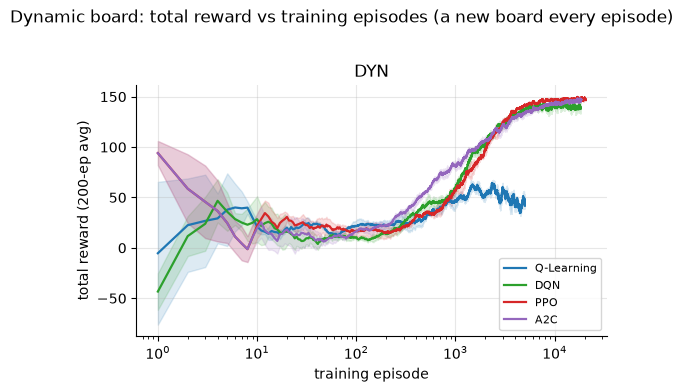

In [24]:
DYN = dict(n=50, max_steps=50 // 3, dynamic=(5, 5), obs_mode="features")
DYN_ALGOS = ["Q-Learning", "DQN", "PPO", "A2C"]


def eval_dynamic(policy, episodes=300, seed=900_000):
    # Play `episodes` games on unseen random boards; compare each game with BFS on that board.
    env, rows = DiceBoardEnv(**DYN), []
    for i in range(episodes):
        env.reset(seed=seed + i)
        bfs = bfs_shortest_path(env.n, env.jumps)[0]
        total, done = 0.0, False
        while not done:
            _, r, term, trunc, _ = env.step(policy(env))
            total += r; done = term or trunc
        rows.append(dict(ret=total, moves=env.t, success=float(term), bfs=bfs,
                         optimal=float(term and env.t == bfs), ratio=env.t / bfs if term else np.nan))
    return pd.DataFrame(rows).mean().to_dict()


def greedy_rule(env):
    dests = [transition(env.pos, d, env.n, env.jumps, env.rewards) for d in range(1, 7)]
    return int(np.argmax([-1 if ev == "invalid" else dest for dest, _, ev in dests]))


def run_dynamic():
    out = {}
    for algo in DYN_ALGOS:
        for seed in SEEDS:
            log, policy = train_any(algo, DYN, seed, 5_000, 150_000, eval_every=0)
            log["final"] = eval_dynamic(policy)
            out[("DYN", algo, seed)] = log
            print(f"{algo:10s} seed {seed}: {log['time']:6.1f}s  win={log['final']['success']:.0%}  "
                  f"moves={log['final']['moves']:.2f}  optimal games={log['final']['optimal']:.0%}")
    return out


DYNRES = cached("dynamic_board", run_dynamic)

rows = []
refs = {"Random policy": random_policy, "Greedy rule (hand-written)": greedy_rule,
        "Q-Learning trained on fixed Board 50": q_policy(CORE[("Board 50", "Q-Learning", 0)]["Q"])}
for name, pol in refs.items():
    f = eval_dynamic(pol)
    rows.append({"policy": name, "win %": f"{100 * f['success']:.1f}", "avg moves": f"{f['moves']:.2f}",
                 "avg return": f"{f['ret']:.1f}", "moves / BFS (won games)": f"{f['ratio']:.2f}",
                 "optimal games %": f"{100 * f['optimal']:.1f}"})
for algo in DYN_ALGOS:
    fs = [DYNRES[("DYN", algo, s)]["final"] for s in SEEDS]
    label = algo + (" (position only)" if algo == "Q-Learning" else " (features)")
    rows.append({"policy": label, "win %": pm([100 * f["success"] for f in fs]),
                 "avg moves": pm([f["moves"] for f in fs], 2), "avg return": pm([f["ret"] for f in fs]),
                 "moves / BFS (won games)": pm([f["ratio"] for f in fs], 2),
                 "optimal games %": pm([100 * f["optimal"] for f in fs]),
                 "train time (s)": pm([DYNRES[("DYN", algo, s)]["time"] for s in SEEDS])})
bfs_avg = eval_dynamic(random_policy)["bfs"]
rows.append({"policy": "BFS with full board knowledge", "win %": "100.0", "avg moves": f"{bfs_avg:.2f}",
             "moves / BFS (won games)": "1.00", "optimal games %": "100.0"})
DYN_TABLE = pd.DataFrame(rows).fillna("").set_index("policy")
DYN_TABLE.to_csv(os.path.join(RESULTS_DIR, "dynamic_board_summary.csv"))
display(DYN_TABLE)
plot_training(DYNRES, ["DYN"], "reward", "total reward (200-ep avg)", algos=DYN_ALGOS, w=200,
              title="Dynamic board: total reward vs training episodes (a new board every episode)")

## 11. Challenge 6 and extra studies (cheap tabular experiments, 10 seeds each)

### 11.1 Reward design (Challenge 6)
Q-Learning on Board 100 with three reward functions:
* **R-v0**: the standard table (+20 ladder), used in all main experiments;
* **R-v1**: no ladder bonus;
* **R-v1 + potential shaping**: $F(s,s')=\gamma\Phi(s')-\Phi(s)$ with $\Phi(p)=20\cdot\frac{p-1}{N-1}$ (and
  $\Phi(\text{goal})=0$). Ng et al. (1999) proved that potential-based shaping **does not change the optimal policy**,
  but it can speed learning up because progress is rewarded immediately.

The long-jump board from Section 3.3 is added to show what R-v0 does to a *learning* agent.

In [25]:
def run_reward_study():
    out = {}
    variants = {"R-v0 (standard)": dict(rewards=REWARDS_V0), "R-v1": dict(rewards=REWARDS_V1),
                "R-v1 + potential shaping": dict(rewards=REWARDS_V1, shaping=20.0)}
    for bname, board in (("Board 100", BOARDS["Board 100"]), ("Long-jump board 100", dict(HACK_BOARD, max_steps=33))):
        opt = OPTIMAL["Board 100"]["moves"] if bname == "Board 100" else bfs_shortest_path(100, HACK_BOARD["jumps"])[0]
        for vname, extra in variants.items():
            for seed in range(10):
                log, policy = train_any("Q-Learning", {**board, **extra}, seed, 3000, None, eval_every=20)
                plain = DiceBoardEnv(**board)                       # judge the final route without shaping
                out[(bname, vname, seed)] = dict(conv=convergence(log, opt)[0], final=evaluate(policy, plain, 1),
                                                 opt=opt)
    return out


RW = cached("reward_study", run_reward_study)
rows = []
for (bname, vname) in dict.fromkeys((k[0], k[1]) for k in RW):
    rs = [RW[(bname, vname, s)] for s in range(10)]
    rows.append({"board": bname, "reward": "R-v0 (standard)" if vname.startswith("R-v0") else vname, "BFS moves": rs[0]["opt"],
                 "converged (of 10)": int(np.sum(~np.isnan([r["conv"] for r in rs]))),
                 "episodes to converge": pm([r["conv"] for r in rs], 0),
                 "final greedy moves": pm([r["final"]["moves"] for r in rs]),
                 "final success %": pm([100 * r["final"]["success"] for r in rs], 0)})
display(pd.DataFrame(rows).set_index(["board", "reward"]))

[cache] loaded results\reward_study.pkl


BFS moves  converged (of 10)  \
board               reward                                                   
Board 100           R-v0 (standard)                   8                 10   
                    R-v1                              8                 10   
                    R-v1 + potential shaping          8                 10   
Long-jump board 100 R-v0 (standard)                   5                 10   
                    R-v1                              5                 10   
                    R-v1 + potential shaping          5                 10   

                                             episodes to converge  \
board               reward                                          
Board 100           R-v0 (standard)                       28 ± 10   
                    R-v1                                 232 ± 41   
                    R-v1 + potential shaping               22 ± 6   
Long-jump board 100 R-v0 (standard)                       48 ± 35   
                    R-v1                                  84 ± 34   
                    R-v1 + potential shaping              54 ± 65   

                                             final greedy moves  \
board               reward                                        
Board 100           R-v0 (standard)                   8.0 ± 0.0   
                    R-v1                              8.0 ± 0.0   
                    R-v1 + potential shaping          8.0 ± 0.0   
Long-jump board 100 R-v0 (standard)                  12.5 ± 6.8   
                    R-v1                              5.0 ± 0.0   
                    R-v1 + potential shaping          5.0 ± 0.0   

                                             final success %  
board               reward                                    
Board 100           R-v0 (standard)                  100 ± 0  
                    R-v1                             100 ± 0  
                    R-v1 + potential shaping         100 ± 0  
Long-jump board 100 R-v0 (standard)                  90 ± 30  
                    R-v1                             100 ± 0  
                    R-v1 + potential shaping         100 ± 0

### 11.2 Can the agent learn with fewer training episodes?
Q-Learning with a reduced episode budget (ε still decays over 60 % of the budget). Share of 10 seeds whose greedy
policy is optimal at the end.

[cache] loaded results\budget_study.pkl


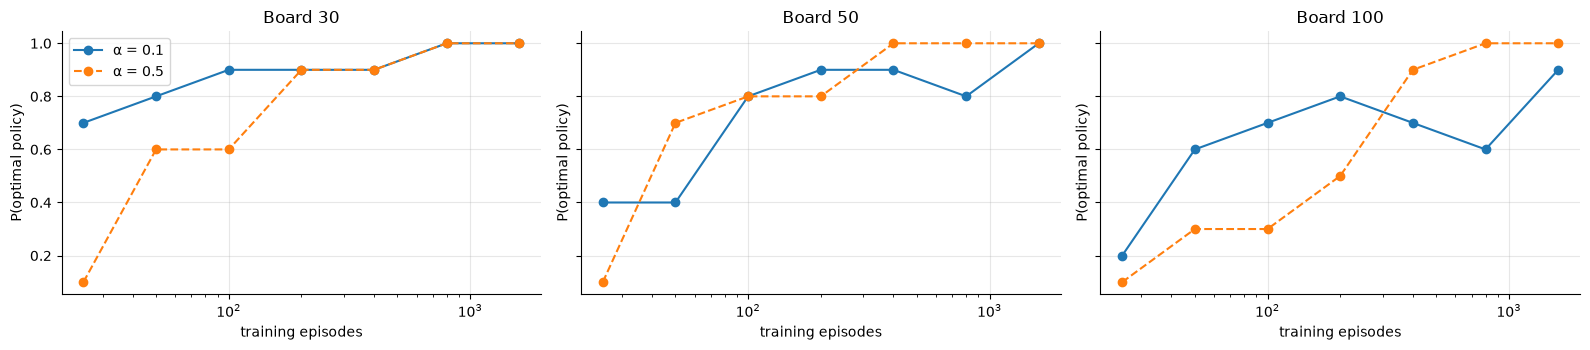

In [26]:
BUDGETS = [25, 50, 100, 200, 400, 800, 1600]


def run_budget():
    out = {}
    for bname, board in BOARDS.items():
        for alpha in (0.1, 0.5):
            for bud in BUDGETS:
                ok = []
                for seed in range(10):
                    log, policy = train_any("Q-Learning", board, seed, bud, None, eval_every=0, alpha=alpha)
                    ok.append(evaluate(policy, DiceBoardEnv(**board), 1)["moves"] <= OPTIMAL[bname]["moves"])
                out[(bname, alpha, bud)] = np.mean(ok)
    return out


BUD = cached("budget_study", run_budget)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, bname in zip(axes, BOARDS):
    for alpha, ls in ((0.1, "-"), (0.5, "--")):
        ax.plot(BUDGETS, [BUD[(bname, alpha, b)] for b in BUDGETS], "o" + ls, label=f"α = {alpha}")
    ax.set_xscale("log"); ax.set_title(bname); ax.set_xlabel("training episodes"); ax.set_ylabel("P(optimal policy)")
axes[0].legend(); plt.tight_layout(); plt.show()

### 11.3 How do the number of snakes and ladders affect learning?
Board 50, 5 ladders and 0–12 snakes, then 5 snakes and 0–10 ladders. Each configuration uses 3 random boards ×
3 seeds, with Q-Learning for 3 000 episodes.

In [27]:
def run_density():
    out = []
    for kind, values in (("snakes", [0, 4, 8, 12]), ("ladders", [0, 3, 6, 10])):
        for v in values:
            for bseed in range(3):
                ns, nl = (v, 5) if kind == "snakes" else (5, v)
                board = dict(n=50, jumps=generate_board(50, ns, nl, seed=100 + bseed), max_steps=50 // 3)
                env = DiceBoardEnv(**board)
                opt = rollout(q_policy(value_iteration(env)), env)["moves"]
                rnd = evaluate(random_policy, env, 300)
                for seed in range(3):
                    log, _ = train_any("Q-Learning", board, seed, 3000, None, eval_every=20)
                    out.append(dict(kind=kind, count=v, board=bseed, seed=seed, opt_moves=opt,
                                    random_success=rnd["success"], conv=convergence(log, opt)[0],
                                    train_success=np.mean(log["success"])))
    return pd.DataFrame(out)


DEN = cached("density_study", run_density)
display(DEN.groupby(["kind", "count"]).agg(optimal_moves=("opt_moves", "mean"), random_success=("random_success", "mean"),
                                            episodes_to_converge=("conv", "mean"),
                                            train_success=("train_success", "mean")).round(2))

[cache] loaded results\density_study.pkl


optimal_moves  random_success  episodes_to_converge  \
kind    count                                                        
ladders 0               9.00            0.11                306.67   
        3               5.33            0.34                 44.44   
        6               4.67            0.51                 35.56   
        10              5.00            0.65                 20.00   
snakes  0               5.00            0.67                 22.22   
        4               5.00            0.48                 42.22   
        8               5.00            0.37                 35.56   
        12              5.00            0.25                 37.78   

               train_success  
kind    count                 
ladders 0               0.80  
        3               0.92  
        6               0.95  
        10              0.97  
snakes  0               0.98  
        4               0.94  
        8               0.92  
        12              0.89

## 12. Discussion

*The numbers quoted below come from the cached run that produced the tables above. If you retrain with
`RETRAIN = True`, small differences between runs are expected.*

### 12.1 Summary of the results

| Setting | Result |
|---|---|
| Core boards 30 / 50 / 100 (R-v0) | **All five algorithms, all 3 seeds** end with the optimal policy: 100 % success, 4 / 5 / 8 moves, which equals BFS, and returns of 139 / 138 / 156. The random policy wins only 31–50 % of games within the step limit. |
| Speed (episodes to converge) | Q-Learning 20–33; SARSA 87–293; DQN 107–180; PPO 120–1 640; A2C 54 on Board 30 but 1 250–2 100 on the larger boards. In wall-clock time the tabular agents train in about 1 s, A2C in 5–26 s, PPO in 12–65 s and DQN in 32–175 s. |
| Random dice (Env. B) | Q-Learning (126.6), DQN (126.5) and SARSA (126.1) match the exact optimum (126.6). PPO (105) and A2C (102) are clearly better than the classic always-move game (47) but still hit about 0.6 snakes per game. Unscaled DQN fails (61 % wins). |
| Larger boards 200 / 400 | All methods find the optimal route. Tabular Q-Learning needs the fewest steps (14k / 58k), then DQN one-hot (31k / 92k), then DQN with features (53k / 100k, and 16 instead of 15 moves on Board 400). |
| Dynamic board (Env. C) | Feature-based PPO wins 100 % of games on unseen boards in 1.08 × the BFS optimum. A2C manages 1.17 × and DQN 1.20 × (91 % wins). Position-only Q-Learning (51 %) and the route memorised on Board 50 (34 %) collapse. A one-step greedy rule reaches 1.02 ×. |
| Snake shield (Board 100) | Exact optimum: return 45.9, versus 10.0 when never using the shield and 29.1 when using it on the first snake. Q-Learning (45.1) and DQN with rewards × 0.01 (44.5) nearly match it by learning to **save** the shield for snakes near the goal. SARSA reaches 42.7. PPO (30.7) and A2C (29.2) only learn "use it at once". DQN with × 0.1 fails (10.7). |
| Two players (Board 50) | With the R-v0-based reward every learner wins only 48–50 % against the classic player: they "stay" to dodge snakes and lose tempo. With a win/lose-only reward, **DQN wins 54.0 %**, the same as the cautious rule (54.1 %) and the best of all learners. The tabular methods (46–48 %) cannot learn the sparse signal over 15 000 states in 30k episodes. |

### 12.2 Comparing the three DRL algorithms
* **DQN** is the most **sample-efficient** deep method: it converges in 107–180 episodes on the core boards, close to
  tabular Q-Learning, because replay reuses every transition many times. It is also the **slowest in wall-clock time**
  (one environment, a gradient step every 4 steps) and the most **fragile**. Its greedy policy temporarily got worse
  mid-training (Section 6.2 plot), and without reward scaling it failed on the stochastic board and on the shield task.
  Once tuned, it reached the exact optimum with random dice, learned the delicate "save the shield" rule, and was the
  **only learner to beat the classic player** in the two-player race. In both stochastic tasks the policy-gradient
  methods settled for simpler policies.
* **PPO** needs more episodes (about 1 100–1 600 on the 50/100 boards), because on-policy data is used for 10 epochs
  and then thrown away. But it was the most **stable** method across seeds and the **best at generalising** on the
  dynamic board (68 % of games exactly optimal). Clipping lets it take safe, repeated updates on a noisy objective.
* **A2C** is the **fastest in wall-clock time** of the three (one cheap gradient step per small batch). It is less
  stable than PPO: its convergence episodes vary a lot between seeds (±1 200 on Board 100), and it was the weakest on
  random dice. This is exactly the difference the clipping and batch reuse of PPO are designed to fix.
* On these small discrete problems the **tabular methods are the right tool**. Deep RL starts to pay off only when
  the state must be **generalised** (dynamic board).

### 12.3 Ten research questions

**1. Why can this game be modelled as an MDP?** The next square and the reward depend only on the current square
and the chosen dice value (plus the current roll in the random version, which is then part of the state). How the
agent reached the square is irrelevant, so the **Markov property** holds. States, actions, transition function,
reward function and discount factor are all well defined (Section 2), and the goal is an absorbing terminal state.

**2. State space vs action space.** The **state space** describes *where the agent is*: $S = \{1,\dots,N\}$ (or
$(p,d)$ pairs with random dice). The **action space** describes *what it can do there*: $A = \{1,\dots,6\}$ (or
{stay, move}). The state space grows with the board ($N$), while the action space is fixed at 6. That is why bigger
boards mostly increase exploration cost, not the size of each decision.

**3. How does the reward function affect the learned policy?** It defines *what* "optimal" means:
* With the standard R-v0 the optimum is "fast **and** through ladders". On the benchmark boards that equals the BFS
  route, but on Board 200 the agent takes 13 moves instead of BFS's 12 to collect an extra +20 ladder.
* On a board with long jumps, R-v0 is **hackable**: the exact optimum loops ladder→snake→ladder forever (Section
  3.3), and 1 of 10 learning agents fell into this loop (Section 11.1: 90 % success, 12.5 ± 6.8 moves).
* Reward also changes **learning speed**. Q-Learning on Board 100 converged in 28 episodes with R-v0 and in 22 with
  potential-based shaping, but needed 232 with R-v1, where nothing but the goal pays. Dense, well-designed rewards
  help, while repeatable bonuses can create unintended behaviour.
* Reward **scale** matters for function approximation: DQN failed on random dice until rewards were divided by 10, and
  on the shield task until they were divided by 100 (Huber-loss bias, Section 8.2).
* The reward must encode the **real objective**. In the two-player race the R-v0-based reward made agents dodge
  snakes at the cost of tempo, and they won only about 50 %. Rewarding only the win (+1 / −1) let DQN reach 54 %.

**4. What is the role of ε-greedy exploration?** Without exploration the agent would repeat the first route that
works and never discover ladders it has not tried. With probability ε a random dice value is chosen, so every
(state, action) pair keeps being visited, which is a condition for Q-Learning to converge. As ε decays from 1.0 to
0.05, the agent moves from exploring to exploiting. The cost is visible in the training metrics: tabular training
success is only 89–96 % even though the greedy policy is 100 %, because some exploratory moves overshoot or hit snakes.

**5. Difference between Q-Learning and SARSA.** Q-Learning is **off-policy**: its target uses
$\max_{a'}Q(s',a')$, the value of the *greedy* policy, whatever the agent actually does next. SARSA is
**on-policy**: its target uses $Q(s',a')$ for the action $a'$ really taken, so it learns the value of the ε-greedy
behaviour itself.

**6. Why might Q-Learning converge to a different policy from SARSA?** Because SARSA's values include the cost of
future exploratory mistakes, it prefers states where a random move is less harmful ("safe" policy, as in cliff
walking). Q-Learning ignores that risk and learns the optimal greedy route. Here the effect is small because the board
has few spots where one wrong roll is catastrophic. With constant ε = 0.2 on Board 100, SARSA earned slightly more
online reward (150.0 vs 149.7) and chose a 9-move route on one of 5 seeds, while Q-Learning always kept the 8-move
optimum. With decaying ε both reach the same optimum, but Q-Learning gets there **much faster** (20–33 vs 87–293
episodes): it learns the greedy route even while behaving almost randomly, whereas SARSA has to wait until ε is small.

**7. How do the number and location of snakes and ladders affect learning?** (Section 11.3)
* **Ladders** shorten the optimal route (9 → about 5 moves) and make learning *faster*: 307 episodes with no ladders,
  about 20–45 with 3–10 ladders, because the +20 reward is an early signal that points towards progress.
* **Snakes** barely change the optimal route when the agent controls the dice (it simply avoids them). They lower the
  random and training success (67 % → 25 % random success, 98 % → 89 % training success) and make convergence a little
  slower (22 → 36–42 episodes).
* **Location** matters more than count: a snake right next to a ladder foot or near the goal punishes exploration
  the most. With random dice, snakes are what force the agent to learn *when to stay*.

**8. Can the agent learn a good policy with fewer training episodes?** Yes, for tabular Q-Learning. On Board 30,
70 % of seeds are already optimal after 25 episodes and 90 % after 100. On Board 100, a larger step size α = 0.5 with
800 episodes is optimal on 100 % of seeds, while α = 0.1 reaches only 90 % with 1 600 (Section 11.2). The core runs converge in
20–33 episodes under our criterion. The deep methods need roughly 100–2 000 episodes, so they are the ones that
benefit from bigger budgets.

**9. What happens when the board size increases?** The number of states grows, episodes get longer, and random
exploration reaches the far squares less often. Steps to converge for Q-Learning grow from about 0.2k (N = 30) to
0.6k (N = 100), 14k (N = 200) and 58k (N = 400). DQN grows more slowly in relative terms, but still needs more steps
(31k / 92k). A table of $400 \times 6$ is tiny, so tabular methods remain best in this range. Function approximation
would only win if the state could not be enumerated, or if knowledge had to transfer between squares or boards.

**10. How does the learned policy compare with the optimal policy obtained using BFS?** On all three benchmark boards
every learned greedy policy uses **exactly the BFS number of moves** (4 / 5 / 8) and the value-iteration optimum
return. The routes can differ from the BFS path (e.g. DQN, PPO and A2C go 1→6→34 instead of 1→26→32 on Board 100),
because several routes have the same length. When the objective is reward rather than roll count, the learned
policy can deliberately be *longer* than BFS (Board 200: 13 vs 12) because it is optimising a different objective.

### 12.4 Research question: BFS can solve the deterministic board, so why use RL?
* **Deterministic board, known rules (Env. A): BFS is simpler and better.** It finds the shortest route instantly,
  with a guarantee and no training. RL reached the same answer, but needed hundreds to thousands of episodes. Here
  RL is a demonstration, not a necessity.
* **Stochastic transitions (Env. B): BFS no longer applies.** There is no single path when the die is random. The
  question becomes *"what should I do in each (square, roll) state?"*, which is a policy and needs expected values.
  If the model is known, dynamic programming (value iteration) solves it. RL (Q-Learning, DQN) reached the same
  optimum **without** being given the transition probabilities, purely from play. That matters when the model is
  unknown or too complex to write down.
* **Dynamic board / limited information (Env. C):** BFS needs the whole board and must be re-run for every new
  board. An RL policy trained on many boards acts immediately on an unseen one, using only local information, and
  PPO came within 8 % of the full-knowledge BFS optimum. A memorised route (tabular Q on a fixed board) does not
  generalise at all.
* **Opponents and long-term resources (Sections 8.2–8.3):** "save the shield or use it now" and "how to play
  against another player" are sequential decisions under uncertainty. A shortest-path search cannot express them at
  all, while value-based RL learned near-optimal answers from play alone.
* **Limitations of RL observed here:** it needs many samples, hyper-parameter care (DQN reward scale), and a sound
  reward design (R-v0 hacking). It is also not automatically better than domain knowledge: the hand-written one-step
  greedy rule (1.02 × BFS) beat every learned policy on the dynamic board. **Use classical planning when the model is
  known and the problem is small and deterministic; use RL when transitions are stochastic or unknown, when the
  environment changes, or when only partial information is available.**

### 12.5 Limitations and possible extensions
* The DRL hyper-parameters are reasonable defaults with light tuning (only the DQN reward scale was changed), not a
  full search. Rankings of training speed could shift with tuning.
* Three seeds give a sense of variance, not statistical significance.
* The two-player agents were trained against one fixed rule-based opponent. Self-play, or training against a pool of
  opponents, would be the natural next step towards a policy that is robust against any player.
* The DQN reward scale was tuned per task (× 0.1 in general, × 0.01 on the shield task). A loss that does not depend
  on the reward magnitude (MSE, or normalised targets) would remove this hyper-parameter.